# Предсказание совершения целевого действия на сайте «СберАвтоподписка»

**Цели работы:**
- разработка пайплайна предобработки данных;
- выбор и оптимизация модели бинарной классификации;
- создание сервиса для онлайн-предсказания вероятности совершения<br>пользователем целевого действия на основе данных Google Analytics.

**Для запуска ноутбука необходимы следующие файлы:**
- `/data/raw/ga_sessions.pkl` (~ 4 Гб)
- `/data/raw/ga_hits.pkl` (~ 380 Мб)

Они отсутствуют в репозитории из-за ограничений на размер.<br>
Перед запуском ноутбука необходимо скачать их по ссылке:<br>
https://drive.google.com/drive/folders/1rA4o6KHH-M2KMvBLHp5DZ5gioF2q7hZw

In [1]:
import time
import pandas as pd
import missingno as msno
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import (
    StandardScaler, OneHotEncoder, FunctionTransformer,
)
from sklearn.model_selection import (
    train_test_split, cross_val_score, GridSearchCV,
    StratifiedKFold, StratifiedShuffleSplit, cross_val_predict
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    roc_auc_score, precision_recall_curve, roc_curve, confusion_matrix
)
from pandas.testing import assert_frame_equal
from sklearn.pipeline import Pipeline

In [2]:
def format_duration(seconds):
    if seconds < 60:
        return f'{seconds:.1f} сек.'
    return f'{seconds / 60:.1f} мин.'

# 1 Data preparation

## 1.1 Считывание исходных файлов

In [3]:
start_read = time.time()
hits = pd.read_pickle('./data/raw/ga_hits.pkl')
sessions = pd.read_pickle('./data/raw/ga_sessions.pkl')
end_read = time.time()
read_duration = format_duration(end_read - start_read)
print('Продолжительность считывания исходных файлов:', read_duration)

Продолжительность считывания исходных файлов: 2.2 мин.


## 1.2 Общий идентификатор session_id

In [4]:
print(f'Количество записей в sessions: {len(sessions)}')
print(f'Кол-во уникальных sessions.session_id: {len(sessions.session_id.unique())}')
print(f'\nКоличество записей в hits: {len(hits)}')
print(f'Кол-во уникальных hits.session_id: {len(hits.session_id.unique())}')

Количество записей в sessions: 1860042
Кол-во уникальных sessions.session_id: 1860042

Количество записей в hits: 15726470
Кол-во уникальных hits.session_id: 1734610


Выводы:
- в таблице sessions нет строк с пустым session_id, все значения разные, повторов нет;
- количество уникальных hits.session_id меньше, чем количество уникальных sessions.session_id, значит есть сессии без событий.

In [5]:
n_sessions_wo_hits = len(sessions[~sessions['session_id'].isin(hits['session_id'])])
print(f'Количество сессий без событий: {n_sessions_wo_hits}')
print(f'Доля сессий без событий: {100 * n_sessions_wo_hits / len(sessions):.1f} %')

n_hits_wo_sessions = len(hits[~hits['session_id'].isin(sessions['session_id'])])
print(f'\nКоличество событий без сессий: {n_hits_wo_sessions}')
print(f'Доля событий без сессий: {100 * n_hits_wo_sessions / len(hits):.2f} %')

Количество сессий без событий: 127776
Доля сессий без событий: 6.9 %

Количество событий без сессий: 41251
Доля событий без сессий: 0.26 %


Выводы:
- события без сессий придётся удалить (автоматически при merge), их невозможно использовать;
- сессии без событий оставим, потому что модель должна уметь предсказывать, произойдёт ли конверсия, а "нулевые" визиты без событий — это как раз отрицательные примеры.

## 1.3 Агрегация событий, объединение с сессиями

Осмотрим таблицу `hits`

In [6]:
hits.head()

,session_id,hit_date,hit_time,hit_number,hit_type,hit_referer,hit_page_path,event_category,event_action,event_label,event_value
0,5639623078712724064.1640254056.1640254056,2021-12-23,597864.0,30,event,NaN,sberauto.com/cars?utm_source_initial=google&ut...,quiz,quiz_show,NaN,None
1,7750352294969115059.1640271109.1640271109,2021-12-23,597331.0,41,event,NaN,sberauto.com/cars/fiat?city=1&city=18&rental_c...,quiz,quiz_show,NaN,None
2,885342191847998240.1640235807.1640235807,2021-12-23,796252.0,49,event,NaN,sberauto.com/cars/all/volkswagen/polo/e994838f...,quiz,quiz_show,NaN,None
3,142526202120934167.1640211014.1640211014,2021-12-23,934292.0,46,event,NaN,sberauto.com/cars?utm_source_initial=yandex&ut...,quiz,quiz_show,NaN,None
4,3450086108837475701.1640265078.1640265078,2021-12-23,768741.0,79,event,NaN,sberauto.com/cars/all/mercedes-benz/cla-klasse...,quiz,quiz_show,NaN,None


In [7]:
hits_summary = pd.DataFrame({
    'dtype': hits.dtypes.values,
    'missing_count': hits.isna().sum(),
    'missing_%': (hits.isna().mean() * 100).round(2),
    'unique_count': hits.nunique().values,
    'unique_ratio_%': (100 * hits.nunique() / len(hits)).round(2)
})
hits_summary

,dtype,missing_count,missing_%,unique_count,unique_ratio_%
session_id,object,0,0.00,1734610,11.03
hit_date,object,0,0.00,226,0.00
hit_time,float64,9160322,58.25,925887,5.89
hit_number,int64,0,0.00,500,0.00
hit_type,object,0,0.00,1,0.00
hit_referer,object,6274804,39.90,37873,0.24
hit_page_path,object,0,0.00,342715,2.18
event_category,object,0,0.00,52,0.00
event_action,object,0,0.00,230,0.00
event_label,object,3760184,23.91,39825,0.25


В задании сказано: "Упакуйте получившуюся модель в сервис, который будет брать на вход все атрибуты, типа `utm_*`, `device_*`, `geo_*`". Значит, модель должна использовать только признаки сессии. Следовательно, для обучения модели из таблицы `hits` требуется извлечь лишь факт совершения одного из целевых действий в рамках сессии. Определим для каждого события, относится ли оно к целевым.

In [8]:
target_list = [
    'sub_car_claim_click', 'sub_car_claim_submit_click',
    'sub_open_dialog_click', 'sub_custom_question_submit_click',
    'sub_call_number_click', 'sub_callback_submit_click',
    'sub_submit_success', 'sub_car_request_submit_click'
]
hits_target = hits[['session_id', 'hit_page_path', 'event_action']].copy()
hits_target['target_hit'] = hits_target['event_action'].isin(target_list).astype(int)
# hit_page_path позже пригодиться

target_hit_counts = hits_target['target_hit'].value_counts()
print(target_hit_counts)
target_hits_ratio = 100 * target_hit_counts[1] / len(hits_target)
print(f'\nTarget hits ratio: {target_hits_ratio:.2f} %')

target_hit
0    15621562
1      104908
Name: count, dtype: int64

Target hits ratio: 0.67 %


Теперь сгруппируем таблицу `target_hits` таким образом, чтобы одной сессии соответствовала только одна строка. Определённый независимо для каждого действия признак `target_hit` агрегируем до уровня сессии в признак `target`, который равен 1, когда в рамках сессии совершено хотя бы одно из целевых действий, иначе 0. Полученную таким образом колонку `target` объединим с таблицей `sessions`, через общий `session_id`.

In [9]:
# target - совершение хотя бы одного из целевых действий за сессию
target = hits_target.groupby('session_id', as_index=False)['target_hit'].max()
target = target.rename(columns={'target_hit': 'target'})
# При объединении таблиц события без сессий отбрасываются
sessions_target = sessions.merge(target, on='session_id', how='left')
sessions_target['target'] = sessions_target['target'].fillna(0).astype(int)

sess_count = len(sessions_target)
print(f'Sessions number: {sess_count}')
target_sessions_ratio = 100 * sessions_target['target'].sum() / sess_count
print(f'Target sessions ratio: {target_sessions_ratio:.2f} %\n')
sessions_target.head()

Sessions number: 1860042
Target sessions ratio: 2.70 %



,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city,target
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Zlatoust,0
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,NaN,385x854,Samsung Internet,Russia,Moscow,0
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Krasnoyarsk,0
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,mobile,None,Xiaomi,NaN,393x786,Chrome,Russia,Moscow,0
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,mobile,None,Xiaomi,NaN,393x786,Chrome,Russia,Moscow,0


In [10]:
aggreg_duration = format_duration(time.time() - end_read)
print('Продолжительность агрегации событий:', aggreg_duration)

Продолжительность агрегации событий: 37.6 сек.


In [11]:
start_save1 = time.time()
sessions_target.to_pickle('./data/processed/sessions_target.pkl')
save1_duration = format_duration(time.time() - start_save1)
print('Продолжительность сохранения сессий с target:', save1_duration)

Продолжительность сохранения сессий с target: 7.0 сек.


## 1.4 Обработка и отбор признаков

### 1.4.1 Считывание файла sessions_target.pkl и разделение на train/test

Если файл `sessions_target.pkl` уже сохранён, то после первых двух ячеек можно продолжить со следующей ячейки ниже.

In [12]:
# Если уже есть 'sessions_target.pkl'
# Можно после первых двух ячеек запускать сразу эту
# Run Selected Sell and All Below

start_read_labeled = time.time()
sessions_target = pd.read_pickle('./data/processed/sessions_target.pkl')
read_labeled_duration = format_duration(time.time() - start_read_labeled)
print('Продолжительность считывания',
      'сессий с target:', read_labeled_duration)
start_prep = time.time()

Продолжительность считывания сессий с target: 2.0 сек.


Разделим данные на тренировочную и тестовую выборки с сохранением доли целевых визитов.

In [13]:
y = sessions_target['target']
df_train_raw, df_test_raw = train_test_split(
    sessions_target,
    test_size=0.2,
    random_state=42,
    shuffle=True,
    stratify=y,   # сохраняем баланс классов
)

### 1.4.2 Отбор признаков по условию задания

В задании сказано: "Упакуйте получившуюся модель в сервис, который будет брать на вход все атрибуты, типа `utm_*`, `device_*`, `geo_*`". Значит остальные колонки (кроме `target`) можно отбросить. Посмотрим, какие колонки попадают под удаление.

In [14]:
prefixes = ('utm_', 'device_', 'geo_', 'target')
columns_to_drop = [c for c in sessions_target.columns if not c.startswith(prefixes)]
columns_to_drop

['session_id', 'client_id', 'visit_date', 'visit_time', 'visit_number']

Удалим эти признаки и осмотрим оставшиеся.

In [15]:
df_train = df_train_raw.drop(columns=columns_to_drop)
df_train.columns

Index(['utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent',
       'utm_keyword', 'device_category', 'device_os', 'device_brand',
       'device_model', 'device_screen_resolution', 'device_browser',
       'geo_country', 'geo_city', 'target'],
      dtype='object')

### 1.4.3 Исследование пропусков, оценка необходимости удаления признаков

Оценим визуально степень заполненности колонок полученного датасета.

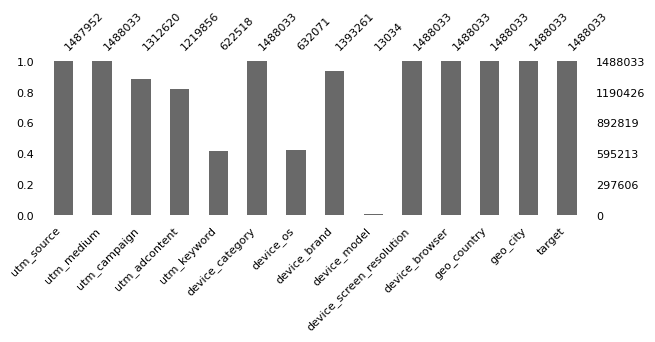

In [16]:
msno.bar(df_train, figsize=(7, 2), fontsize=8);

Колонка `device_model` содержит менее 1% заполненых значений. Удаляем эту колонку однозначно и безжалостно.

In [17]:
df_train = df_train.drop(columns='device_model')

Теперь посмотрим на пропуски визуально, с учётом того, в каких строках они встречаются.

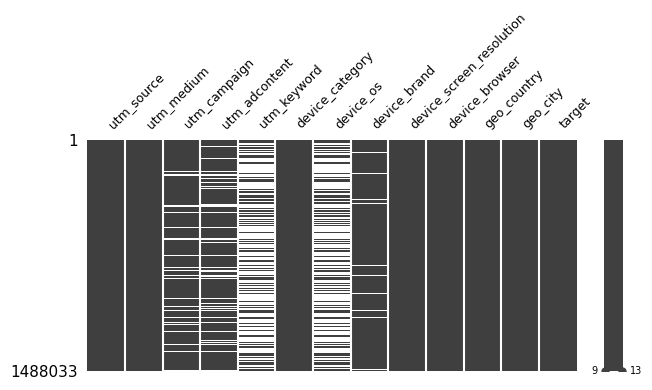

In [18]:
msno.matrix(df_train, figsize=(7, 3), fontsize=9);

Посмотрим распределение строк по количеству пропусков в них.

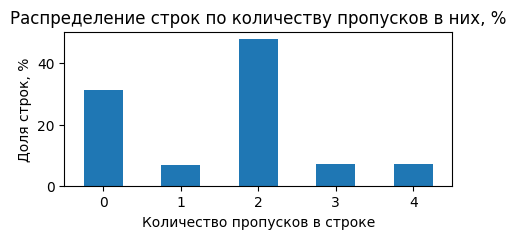

In [19]:
n_nans_rows_share = (
    100 * df_train
    .isna()
    .sum(axis=1)
    .value_counts(normalize=True)
    .sort_index()
).to_frame(name='rows_share_%').rename_axis('n_nans')

n_nans_rows_share.plot(kind='bar', figsize=(5, 2), legend=False);
plt.title('Распределение строк по количеству пропусков в них, %')
plt.xlabel('Количество пропусков в строке')
plt.ylabel('Доля строк, %')
plt.xticks(rotation=0);

In [20]:
n_nans_rows_share.style.format("{:.1f}")

,rows_share_%
n_nans,
0,31.1
1,6.9
2,47.9
3,7.1
4,7.0


In [21]:
two_nans_rows_share, = 100 * (
    n_nans_rows_share['rows_share_%'][2]
    / n_nans_rows_share[1:].sum()
)
print(
    f'Среди строк с пропусками доля строк с двумя пропусками: '
    f'{two_nans_rows_share:.0f} %'
)

Среди строк с пропусками доля строк с двумя пропусками: 70 %


Выяснено следующее:
- доля полностью заполненных строк 31 %;
- большинство (70 %) строк с пропусками содержит 2 пропуска;
- максимальное количество пропусков в одной строке — четре.<br>

Теперь посмотрим какие именно признаки одновременно отсутствуют в строках с разным количеством пропусков.<br>
Начнём с худшего случая, когда отсутствует максимальное количесто признаков — четыре.

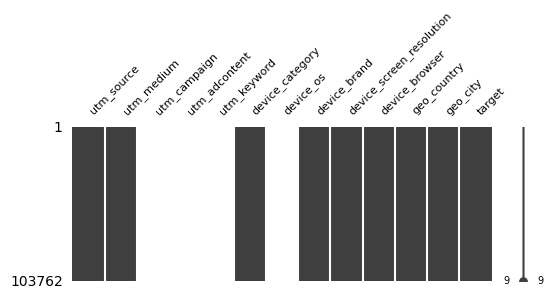

In [22]:
rows_with_4_nans = df_train[
    df_train.isna().sum(axis=1) == 4
]
msno.matrix(rows_with_4_nans, figsize=(6, 2), fontsize=8);

In [23]:
def nan_columns(rows_with_nans):
    columns = rows_with_nans.columns.to_numpy()
    isna_mask = rows_with_nans.isna().to_numpy()
    row_nans = [tuple(columns[row_isna_mask]) for row_isna_mask in isna_mask]
    return (
        100 * pd.Series(row_nans)
        .value_counts(normalize=True)
        .to_frame(name='rows_share_%')
        .rename_axis('nan_columns')
    ).style.format("{:.2f}")

nan_columns(rows_with_4_nans)

,rows_share_%
nan_columns,
"('utm_campaign', 'utm_adcontent', 'utm_keyword', 'device_os')",99.98
"('utm_campaign', 'utm_adcontent', 'utm_keyword', 'device_brand')",0.02


Практически во всех строках с четырмя пропусками одновременно отсутствуют одни и те же признаки: `utm_campaign`, `utm_adcontent`, `utm_keyword` и `device_os`. Посмотрим, какие признаки отсутствуют в строках с меньшим количеством пропусков.

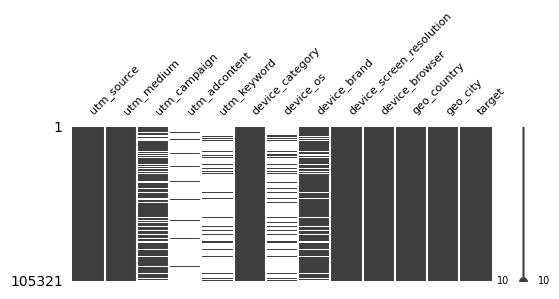

In [24]:
rows_with_3_nans = df_train[
    df_train.isna().sum(axis=1) == 3
]
msno.matrix(rows_with_3_nans, figsize=(6, 2), fontsize=8);

In [25]:
nan_columns(rows_with_3_nans)

,rows_share_%
nan_columns,
"('utm_adcontent', 'utm_keyword', 'device_os')",73.58
"('utm_campaign', 'utm_adcontent', 'device_brand')",15.37
"('utm_campaign', 'utm_keyword', 'device_os')",5.42
"('utm_campaign', 'utm_adcontent', 'utm_keyword')",5.21
"('utm_adcontent', 'utm_keyword', 'device_brand')",0.38
"('utm_source', 'utm_adcontent', 'device_brand')",0.03
"('utm_campaign', 'utm_keyword', 'device_brand')",0.01


Здесь в подавляющем большинстве случаев отсутствуют все те же признаки, но иногда ещё отсутствует `device_brand`. Посмотрим на самый многочисленный вариант строки с пропусками - строки с двумя пропусками. Их доля составляет 70% от всех строк с пропусками.

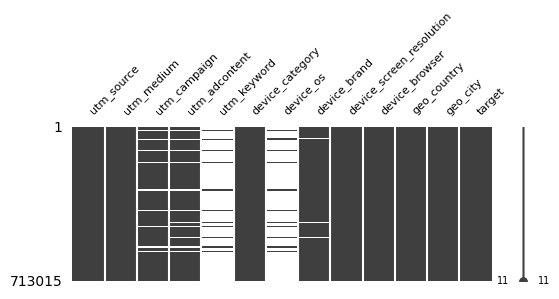

In [26]:
rows_with_2_nans = df_train[
    df_train.isna().sum(axis=1) == 2
]
msno.matrix(rows_with_2_nans, figsize=(6, 2), fontsize=8);

In [27]:
nan_columns(rows_with_2_nans)

,rows_share_%
nan_columns,
"('utm_keyword', 'device_os')",93.83
"('utm_campaign', 'utm_adcontent')",5.08
"('utm_adcontent', 'device_brand')",0.54
"('utm_adcontent', 'utm_keyword')",0.43
"('utm_campaign', 'device_brand')",0.08
"('utm_keyword', 'device_brand')",0.02
"('utm_campaign', 'utm_keyword')",0.01
"('utm_source', 'device_brand')",0.00


Среди строк с пропусками наиболее многочислены строки с пустыми признакмми `utm_keyword`, `device_os`. Для полноты картины посмотрим на распределение пустых признаков в строках с одним пропуском.

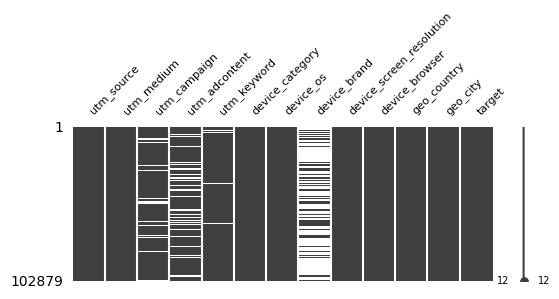

In [28]:
rows_with_1_nan = df_train[
    df_train.isna().sum(axis=1) == 1
]
msno.matrix(rows_with_1_nan, figsize=(6, 2), fontsize=8);

In [29]:
nan_columns(rows_with_1_nan)

,rows_share_%
nan_columns,
"('device_brand',)",71.43
"('utm_adcontent',)",21.01
"('utm_campaign',)",7.19
"('utm_keyword',)",0.33
"('utm_source',)",0.04


Здесь в подавляющем большинстве случаев отсутствует признак `device_brand`.<br><br>

Исследование пропусков показало, что они концентрируются в ограниченном числе одних и тех же признаков, а не распределены случайно по всем столбцам. Итоговый вывод — удаляем только пустую колонку `device_model`. Переходим к заполнению пропусков.

### 1.4.4 Заполнение пропусков

Осмотрим все признаки с пропусками. Задача этого раздел - заполнить все пропуски.

In [30]:
df = df_train
summary = pd.DataFrame({
    'dtype': df.dtypes.values,
    'missing_count': df.isna().sum(),
    'missing_%': (df.isna().mean() * 100).round(2),
    'unique_count': df.nunique().values,
    'unique_ratio_%': (100 * df.nunique() / len(df)).round(2)
})
summary[summary.missing_count > 0]

,dtype,missing_count,missing_%,unique_count,unique_ratio_%
utm_source,object,81,0.01,280,0.02
utm_campaign,object,175413,11.79,401,0.03
utm_adcontent,object,268177,18.02,272,0.02
utm_keyword,object,865515,58.17,1153,0.08
device_os,object,855962,57.52,13,0.00
device_brand,object,94772,6.37,195,0.01


#### 1.4.4.1 Признак `utm_source`

In [31]:
print(f'Доля пропусков: '
      f'{(df_train['utm_source'].isna().mean() * 100).round(2)} %')
df_train['utm_source'].value_counts(dropna=False).head(10)

Доля пропусков: 0.01 %


utm_source
ZpYIoDJMcFzVoPFsHGJL    463119
fDLlAcSmythWSCVMvqvL    240689
kjsLglQLzykiRbcDiGcD    212894
MvfHsxITijuriZxsqZqt    149008
BHcvLfOaCWvWTykYqHVe     92806
bByPQxmDaMXgpHeypKSM     81865
QxAxdyPLuQMEcrdZWdWb     41214
aXQzDWsJuGXeBXexNHjc     24776
jaSOmLICuBzCFqHfBdRg     23310
RmEBuqrriAfAVsLQQmhk     22504
Name: count, dtype: int64

Признак закодирован, в методических указаниях к работе указана следующая информация:<br>
"Реклама в социальных сетях — все визиты с ga_sessions.utm_source in<br>
('QxAxdyPLuQMEcrdZWdWb', 'MvfHsxITijuriZxsqZqt', 'ISrKoXQCxqqYvAZICvjs',<br>
IZEXUFLARCUMynmHNBGo', 'PlbkrSYoHuZBWfYjYnfw','gVRrcxiDQubJiljoTbGm')."<br>

Эту информацию используем позже в 1.5.2. Пока только заполним пропуски в этом признаке значением `unknown`.

In [32]:
def fillna_unknown(df, feature):
    df[feature] = df[feature].fillna('unknown')
    if not df[feature].isna().sum():
        print(f'Признак {feature} полностью заполнен.')

In [33]:
fillna_unknown(df_train, 'utm_source')

Признак utm_source полностью заполнен.


#### 1.4.4.2 Признак `utm_campaign`

In [34]:
print(f'Доля пропусков: '
      f'{(df_train['utm_campaign'].isna().mean() * 100).round(1)} %')
df_train['utm_campaign'].value_counts(dropna=False).head(10)

Доля пропусков: 11.8 %


utm_campaign
LTuZkdKfxRGVceoWkVyg    370795
LEoPHuyFvzoNfnzGgfcd    259333
FTjNLDyTrXaWYgZymFkV    197822
NaN                     175413
gecBYcKZCPMcVYdSSzKP    107345
TmThBvoCcwkCZZUWACYq     21305
okTXSMadDkjvntEHzIjp     19652
XHNUiSKKGTEpSAlaVMFQ     19522
SgIUDYUKnyWHVowUOqid     18315
sbJRYgVfvcnqKJNDDYIr     16147
Name: count, dtype: int64

Признак `utm_campaign` зашифрован и содержит около 12 % пропусков — визиты без рекламной разметки.<br>
Заполняем пропуски значением `'unknown'`.

In [35]:
fillna_unknown(df_train, 'utm_campaign')

Признак utm_campaign полностью заполнен.


#### 1.4.4.3 Признак `utm_adcontent`

In [36]:
print(f'Доля пропусков: '
      f'{(df_train['utm_adcontent'].isna().mean() * 100).round(1)} %')
df_train['utm_adcontent'].value_counts(dropna=False).head(10)

Доля пропусков: 18.0 %


utm_adcontent
JNHcPlZPxEMWDnRiyoBf    805432
NaN                     268177
vCIpmpaGBnIQhyYNkXqp    145039
xhoenQgDQsgfEPYNPwKO     90409
PkybGvWbaqORmxjNunqZ     48411
LLfCasrxQzJIyuldcuWy     19427
TuyPWsGQruPMpKvRxeBF     14558
UxrnyMlRBSOhOjytXnMG     10807
dUuXlWzvmhDSyclWRhNP      8197
yYdBRbPmBMUZHXwqGxNx      7697
Name: count, dtype: int64

Признак зашифрован, в методических указаниях к работе не описан.<br>
Содержит 18 % пропусков. Заполняем пропуски значением `'unknown'`.

In [37]:
fillna_unknown(df_train, 'utm_adcontent')

Признак utm_adcontent полностью заполнен.


#### 1.4.4.4 Признак `utm_keyword`

In [38]:
print(f'Доля пропусков: '
      f'{(df_train['utm_keyword'].isna().mean() * 100).round(1)} %')
df_train['utm_keyword'].value_counts(dropna=False).head(10)

Доля пропусков: 58.2 %


utm_keyword
NaN                     865515
puhZPIYqKXeFPaUviSjo    405761
aXQzDWsJuGXeBXexNHjc     19444
pHqgLcdBQPSLcrTpLkdr     11050
ITfrGJNwVsHBGJMAKoct     10670
hAmNSZmQkKQKAjZEGlgb      9004
UKNBOHebRIIsQRsjNKay      8704
IGUCNvHlhfHpROGclCit      6013
RkpOyeEPgcMBSDuHLQcj      5541
JajANoFxoqXfKRNBUhzx      5416
Name: count, dtype: int64

Признак зашифрован, лидирует по количеству пропусков - 58.2 %.<br>
Это не потеря данных, а индикатор визита не из контекстной рекламы. Заполняем пропуски значением `'unknown'`.

In [39]:
fillna_unknown(df_train, 'utm_keyword')

Признак utm_keyword полностью заполнен.


#### 1.4.4.5 Признак `device_os`

In [40]:
print(f'Доля пропусков: '
      f'{(df_train['device_os'].isna().mean() * 100).round(1)} %')
df_train['device_os'].value_counts(dropna=False)

Доля пропусков: 57.5 %


device_os
None             855962
Android          371286
iOS              165959
Windows           70554
Macintosh         19802
Linux              4079
(not set)           284
Chrome OS            68
BlackBerry           20
Tizen                 7
Windows Phone         4
Samsung               4
Firefox OS            3
Nokia                 1
Name: count, dtype: int64

Заполняем пропуски значением `'unknown'`.

In [41]:
fillna_unknown(df_train, 'device_os')

Признак device_os полностью заполнен.


#### 1.4.4.6 Признак `device_brand`

In [42]:
print(f'Доля пропусков: '
      f'{(df_train['device_brand'].isna().mean() * 100).round(1)} %')
df_train['device_brand'].value_counts().head(10)

Доля пропусков: 6.4 %


device_brand
Apple        441303
Samsung      265835
Xiaomi       231129
             198441
Huawei       148475
Realme        15182
(not set)     14042
OPPO          10740
Vivo           9455
OnePlus        8004
Name: count, dtype: int64

Сюрприз! Пустые строки! Посмотрим, какая доля значений отсутствует с учётом пустых строк

In [43]:
device_brand = df_train['device_brand']
print(f'Совокупная доля пропусков и пустых строк: {100* (
    device_brand.isna().sum() + (device_brand == '').sum()
) / len(device_brand):.1f} %')

Совокупная доля пропусков и пустых строк: 19.7 %


Убедимся, что в других признаках нет пустых строк. Выше таких проверок не было.

In [44]:
(df_train=='').sum()

utm_source                       0
utm_medium                       0
utm_campaign                     0
utm_adcontent                    0
utm_keyword                      0
device_category                  0
device_os                        0
device_brand                198441
device_screen_resolution         0
device_browser                   0
geo_country                      0
geo_city                         0
target                           0
dtype: int64

Признак `device_brand` определяется только для мобильных устройств, где браузер передаёт информацию о бренде в user-agent. Для десктопных визитов таких данных просто нет. Заполняем как пропуски, так и пустые строки значением `'unknown'`.

In [45]:
df_train['device_brand'] = (df_train['device_brand']
                            .replace('', 'unknown').fillna('unknown')
)

Окончательно проверяем весь датасет на наличие пропусков и пустых строк

In [46]:
print(f'Наличие пропусков: '
      f'{df_train.isna().any().any()}')
print(f'Наличие пустых строк: '
      f'{(df_train == '').any().any()}')

Наличие пропусков: False
Наличие пустых строк: False


### 1.4.5 Exploratory data analysis

#### 1.4.5.1 Общий осмотр датафрейма

Осмотрим имеющиеся на данном этапе признаки.

In [47]:
pd.DataFrame({
    'dtype': df_train.dtypes,
    '(not_set)_count': (df_train == '(not set)').sum(),
    '(none)_count': (df_train == '(none)').sum(),
    'unknown_count': (df_train == 'unknown').sum(),
    'unique_count': df_train.nunique(),
    'freq_cats_count': [
        (df_train[col]
         .value_counts(normalize=True) >= 0.01
        ).sum()
        for col in df_train.columns
    ]
}).head(-1)

,dtype,(not_set)_count,(none)_count,unknown_count,unique_count,freq_cats_count
utm_source,object,0,0,81,281,12
utm_medium,object,369,240689,0,56,8
utm_campaign,object,0,0,175413,402,10
utm_adcontent,object,0,0,268177,273,6
utm_keyword,object,0,0,865515,1154,3
device_category,object,0,0,0,3,2
device_os,object,284,0,855962,14,5
device_brand,object,14042,0,293213,195,6
device_screen_resolution,object,7,0,0,4492,25
device_browser,object,11,0,0,52,7


Оказалось, что в датафрейме есть значения `(not set)`. В UTM-признаках значение `(not set)` является не пропуском, а реальной категорией трафика в логике Google Analytics. Оно означает, что пользователь пришёл без UTM-метки, и это — отдельный, осмысленный тип источника/канала, отличающийся по поведению от промо-переходов. Поэтому у признака `utm_medium` не будем заменять `(not set)` на `unknown`. У остальных признаков `(not set)` — это отсутствующая информация, поэтому заменим на `unknown`. Теперь по очереди внимательно рассмотрим каждый признак, оценим связь с целевой переменной, в случае необходимости, объединим малочисленные категории и подумаем о возможных дополнительных преобразованиях признаков.

#### 1.4.5.2 Авторские функии

In [48]:
def conv_distr(df, feature):
    return pd.DataFrame({
        'conv_rate_%': (100 * df
            .groupby(feature)['target']
            .mean()
            .round(4)),
        'sessions_count': df[feature].value_counts()
    }).sort_values('conv_rate_%', ascending=False)

In [49]:
def top_freq_cats(column, freq=0.01):
    counts = column.value_counts()
    shares = column.value_counts(normalize=True)
    df = pd.DataFrame({
        'count': counts,
        'share': shares.round(4),
    }).query('share >= 0.01')
    return df

In [50]:
def rare_to_other(df, feature, top):
    df[feature] = (df[feature]
        .where(df[feature].isin(top.index
        ), 'other'))

In [51]:
def plot_feature_barh(column, size, log=False, top=False):
    counts = column.value_counts().sort_values()
    if top: counts = counts.tail(top)
    plt.figure(figsize=size)
    if log: plt.xscale('log')
    plt.barh(counts.index, counts.values);
    plt.yticks(fontsize=7);
    plt.title(f'Распределение значений'
              f'\nпризнака {column.name}', fontsize=10)
    plt.xlabel('Количество строк')
    plt.ylabel('Значение признака')
    plt.show()

In [52]:
def not_set_to_unknown(df, feature):
    not_set_count = (df[feature] == '(not set)').sum()
    df.loc[:, feature] = df[feature].replace('(not set)', 'unknown')
    if not (df[feature] == '(not set)').any():
        print(f'Количество замен (not set) -> unknown: {not_set_count}')
    else:
        print('Ошибка! Почему-то всё ещё есть значения (not set).')

#### 1.4.5.3 Признак `utm_source`

Посмотрим на распределение конверсии по признаку.

In [53]:
utm_source_conv_distr = conv_distr(df_train, 'utm_source')
utm_source_conv_distr.head()

,conv_rate_%,sessions_count
utm_source,,
YpBKcihLLfFjWuxOLfvW,100.0,1
fJCYsujgSxIHFbOmgDdN,87.5,8
CqeIpFwJscTsZoYXdHsP,50.0,2
juYouSPHPfKdXivEPJjt,50.0,2
XzfzEBYZWgSDtJNXOadn,50.0,2


Наблюдаются аномально высокие значения конверсии (вплоть до 100 %), что связано с недостаточным размером выборок у некоторых значений признака. Для получения надёжных оценок нужны достаточно многочисленные категории. Осмотрим значения, доля которых не меньше 1% от всех записей.

In [54]:
utm_source_top_freq = top_freq_cats(df_train['utm_source'])
utm_source_top_freq

,count,share
utm_source,,
ZpYIoDJMcFzVoPFsHGJL,463119,0.3112
fDLlAcSmythWSCVMvqvL,240689,0.1617
kjsLglQLzykiRbcDiGcD,212894,0.1431
MvfHsxITijuriZxsqZqt,149008,0.1001
BHcvLfOaCWvWTykYqHVe,92806,0.0624
bByPQxmDaMXgpHeypKSM,81865,0.0550
QxAxdyPLuQMEcrdZWdWb,41214,0.0277
aXQzDWsJuGXeBXexNHjc,24776,0.0167
jaSOmLICuBzCFqHfBdRg,23310,0.0157


Заменим остальные редкие значения на одно значение `other`, т.е. объединим малочисленные категории в одну, как это делает `OneHotEncoder` с параметром `min_frequency`=0.01. Минимальное значение частоты пока выбираем произвольно, ниже оно будет оптимизировано.

In [55]:
rare_to_other(df_train, 'utm_source', utm_source_top_freq)

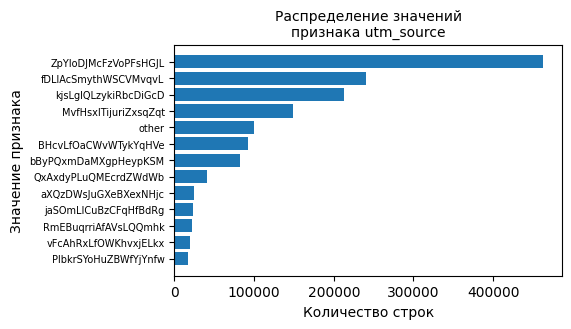

In [56]:
plot_feature_barh(df_train['utm_source'], size=(5, 3))

Повторно рассмотрим распределение конверсии, теперь без малочисленных выборок.

In [57]:
conv_distr(df_train, 'utm_source')

,conv_rate_%,sessions_count
utm_source,,
aXQzDWsJuGXeBXexNHjc,5.82,24776
bByPQxmDaMXgpHeypKSM,5.45,81865
fDLlAcSmythWSCVMvqvL,3.50,240689
BHcvLfOaCWvWTykYqHVe,3.33,92806
ZpYIoDJMcFzVoPFsHGJL,2.77,463119
QxAxdyPLuQMEcrdZWdWb,2.71,41214
kjsLglQLzykiRbcDiGcD,2.37,212894
other,1.57,99665
jaSOmLICuBzCFqHfBdRg,1.33,23310


Существенный разброс значений конверсии между категориями признака `utm_source` (0.22–5.82%) при наличии массовых источников как с высокой, так и с низкой конверсией указывает на высокую информативность данного признака.

#### 1.4.5.4 Признак `utm_medium`

Признак `utm_medium` содержит тип рекламного канала, по которому пользователь перешёл на сайт. Аналогично предыдущему признаку рассмотрим категории с численностью не менее 1% от всех записей.

In [58]:
utm_meduim_top_freq = top_freq_cats(df_train['utm_medium'])
utm_meduim_top_freq

,count,share
utm_medium,,
banner,442162,0.2971
cpc,347605,0.2336
(none),240689,0.1617
cpm,193435,0.1300
referral,121487,0.0816
organic,50424,0.0339
email,23308,0.0157
push,22467,0.0151


Объединим редкие категрии и посмотрим на распределение значений признака.

In [59]:
rare_to_other(df_train, 'utm_medium', utm_meduim_top_freq)

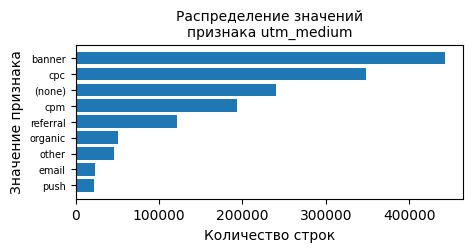

In [60]:
plot_feature_barh(df_train['utm_medium'], size=(5, 2))

Посмотрим на распределение конверсии.

In [61]:
utm_medium_conv_distr = conv_distr(df_train, 'utm_medium')
utm_medium_conv_distr

,conv_rate_%,sessions_count
utm_medium,,
referral,5.39,121487
(none),3.50,240689
organic,3.28,50424
push,2.86,22467
banner,2.74,442162
cpc,2.20,347605
other,1.94,46456
email,1.33,23308
cpm,1.03,193435


Несмотря на меньший разброс значений по сравнению с `utm_source`, различия в конверсии между категориями признака `utm_medium` (1.03–5.39%) при наличии массовых каналов с различной конверсией свидетельствуют о его информативности.

#### 1.4.5.5 Признак `utm_campaign`

Смотрим категории с численностью не менее 1% от всех записей.

In [62]:
utm_campaign_top_freq = top_freq_cats(df_train['utm_campaign'])
utm_campaign_top_freq

,count,share
utm_campaign,,
LTuZkdKfxRGVceoWkVyg,370795,0.2492
LEoPHuyFvzoNfnzGgfcd,259333,0.1743
FTjNLDyTrXaWYgZymFkV,197822,0.1329
unknown,175413,0.1179
gecBYcKZCPMcVYdSSzKP,107345,0.0721
TmThBvoCcwkCZZUWACYq,21305,0.0143
okTXSMadDkjvntEHzIjp,19652,0.0132
XHNUiSKKGTEpSAlaVMFQ,19522,0.0131
SgIUDYUKnyWHVowUOqid,18315,0.0123


Объединим редкие категрии и посмотрим на распределение значений признака.

In [63]:
rare_to_other(df_train, 'utm_campaign', utm_campaign_top_freq)

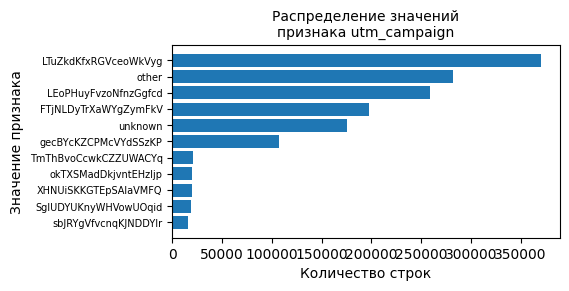

In [64]:
plot_feature_barh(df_train['utm_campaign'], size=(5, 2.5))

Посмотрим на распределение конверсии.

In [65]:
utm_campaign_conv_distr = conv_distr(df_train, 'utm_campaign')
utm_campaign_conv_distr

,conv_rate_%,sessions_count
utm_campaign,,
LTuZkdKfxRGVceoWkVyg,4.10,370795
gecBYcKZCPMcVYdSSzKP,3.39,107345
unknown,3.27,175413
LEoPHuyFvzoNfnzGgfcd,2.90,259333
sbJRYgVfvcnqKJNDDYIr,2.70,16147
other,1.77,282384
SgIUDYUKnyWHVowUOqid,1.69,18315
XHNUiSKKGTEpSAlaVMFQ,1.68,19522
FTjNLDyTrXaWYgZymFkV,0.98,197822


Признак `utm_campaign` демонстрирует выраженную вариативность конверсии между кампаниями (0.31–4.10%) при значительных объёмах наблюдений, что подтверждает его высокую информативность.

#### 1.4.5.6 Признак `utm_adcontent`

Признак `utm_adcontent` не описан в методических указаниях к работе. Предполагаю, что это идентификатор рекламного креатива (варианта объявления). Смотрим категории с численностью не менее 1% от всех записей.

In [66]:
utm_adcontent_top_freq = top_freq_cats(df_train['utm_adcontent'])
utm_adcontent_top_freq

,count,share
utm_adcontent,,
JNHcPlZPxEMWDnRiyoBf,805432,0.5413
unknown,268177,0.1802
vCIpmpaGBnIQhyYNkXqp,145039,0.0975
xhoenQgDQsgfEPYNPwKO,90409,0.0608
PkybGvWbaqORmxjNunqZ,48411,0.0325
LLfCasrxQzJIyuldcuWy,19427,0.0131


Объединим редкие категрии и посмотрим на распределение значений признака.

In [67]:
rare_to_other(df_train, 'utm_adcontent', utm_adcontent_top_freq)

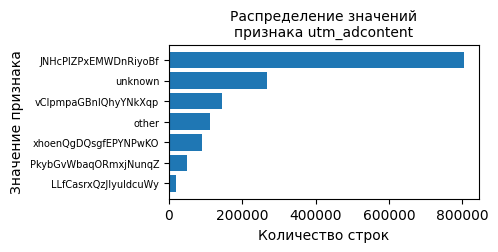

In [68]:
plot_feature_barh(df_train['utm_adcontent'], size=(4, 2))

Посмотрим на распределение конверсии.

In [69]:
conv_distr(df_train, 'utm_adcontent')

,conv_rate_%,sessions_count
utm_adcontent,,
JNHcPlZPxEMWDnRiyoBf,3.38,805432
unknown,2.60,268177
vCIpmpaGBnIQhyYNkXqp,2.17,145039
PkybGvWbaqORmxjNunqZ,1.59,48411
xhoenQgDQsgfEPYNPwKO,1.12,90409
other,0.98,111138
LLfCasrxQzJIyuldcuWy,0.29,19427


Признак `utm_adcontent` демонстрирует выраженную вариативность конверсии между категориями (0.29–3.38%), что подтверждает его информативность.

#### 1.4.5.7 Признак `utm_keyword`

Смотрим категории с численностью не менее 1% от всех записей.

In [70]:
utm_keyword_top_freq = top_freq_cats(df_train['utm_keyword'])
utm_keyword_top_freq

,count,share
utm_keyword,,
unknown,865515,0.5817
puhZPIYqKXeFPaUviSjo,405761,0.2727
aXQzDWsJuGXeBXexNHjc,19444,0.0131


Объединим редкие категрии и посмотрим на распределение значений признака.

In [71]:
rare_to_other(df_train, 'utm_keyword', utm_keyword_top_freq)

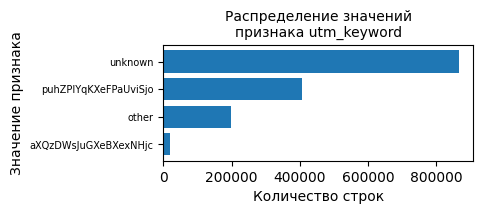

In [72]:
plot_feature_barh(df_train['utm_keyword'], size=(4, 1.5))

Объединение категорий прошло успешно, теперь смотрим на распределение конверсии.

In [73]:
conv_distr(df_train, 'utm_keyword')

,conv_rate_%,sessions_count
utm_keyword,,
unknown,3.2,865515
puhZPIYqKXeFPaUviSjo,2.2,405761
other,1.8,197313
aXQzDWsJuGXeBXexNHjc,0.3,19444


Несмотря на наличие разброса значений (0.3–3.2%), основная часть наблюдений сосредоточена в нескольких категориях с близкими значениями конверсии, что указывает на умеренную информативность данного признака.

#### 1.4.5.8 Признак `device_category`

У этого признака всего три категории.

In [74]:
df_train['device_category'].unique().tolist()

['desktop', 'mobile', 'tablet']

Поскольку целью является единообразная обработка всех признаков, для данного признака, несмотря на малое число категорий, также смотрим категории с численностью не менее 1% от всех записей.

In [75]:
device_category_top_freq = top_freq_cats(df_train['device_category'])
device_category_top_freq

,count,share
device_category,,
mobile,1180449,0.7933
desktop,292974,0.1969


Несмотря на то, что редкая категория получилась всего одна, для единообразия выполним процедуру объединения в 'other' и рассмотрим распределение значений признака.

In [76]:
rare_to_other(df_train, 'device_category', device_category_top_freq)

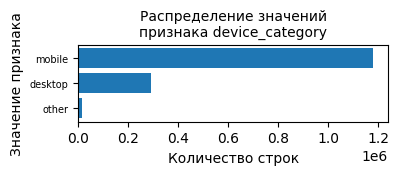

In [77]:
plot_feature_barh(df_train['device_category'], size=(4, 1))

Смотрим распределение конверсии.

In [78]:
conv_distr(df_train, 'device_category')

,conv_rate_%,sessions_count
device_category,,
desktop,3.14,292974
mobile,2.60,1180449
other,2.25,14610


Признак `device_category` демонстрирует умеренные различия в конверсии между основными категориями (desktop и mobile), что указывает на ограниченную информативность.

#### 1.4.5.9 Признак `device_os`

В соответствии с принятым ранее решением, заменяем значени `(not set)` на `unknown`.

In [79]:
not_set_to_unknown(df_train, 'device_os')

Количество замен (not set) -> unknown: 284


Смотрим категории с численностью не менее 1% от всех записей.

In [80]:
device_os_top_freq = top_freq_cats(df_train['device_os'])
device_os_top_freq

,count,share
device_os,,
unknown,856246,0.5754
Android,371286,0.2495
iOS,165959,0.1115
Windows,70554,0.0474
Macintosh,19802,0.0133


Объединим редкие категрии и посмотрим на распределение значений признака.

In [81]:
rare_to_other(df_train, 'device_os', device_os_top_freq)

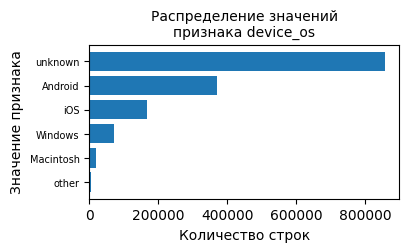

In [82]:
plot_feature_barh(df_train['device_os'], size=(4, 2))

Смотрим распределение конверсии.

In [83]:
conv_distr(df_train, 'device_os')

,conv_rate_%,sessions_count
device_os,,
unknown,3.22,856246
Macintosh,3.08,19802
Android,2.03,371286
iOS,1.90,165959
Windows,1.86,70554
other,1.51,4186


Категория `device_os = unknown` демонстрирует наибольшую конверсию. Вероятно, значение `unknown` связано с переходами из встроенных браузеров приложений и WebView. Такой трафик формируется преимущественно из переходов по внутренним ссылкам, уведомлениям и сообщениям, а не в результате общего браузинга.<br>
Доминирование категории `unknown` при умеренных различиях в конверсии между основными категориями (1.86–3.22%) ограничивает информативность признака.

#### 1.4.5.10 Признак `device_brand`

В соответствии с принятым ранее решением, заменяем значени `(not set)` на `unknown`.

In [84]:
not_set_to_unknown(df_train, 'device_brand')

Количество замен (not set) -> unknown: 14042


Смотрим категории с численностью не менее 1% от всех записей.

In [85]:
device_brand_top_freq = top_freq_cats(df_train['device_brand'])
device_brand_top_freq

,count,share
device_brand,,
Apple,441303,0.2966
unknown,307255,0.2065
Samsung,265835,0.1786
Xiaomi,231129,0.1553
Huawei,148475,0.0998
Realme,15182,0.0102


Объединим редкие категрии и посмотрим на распределение значений признака.

In [86]:
rare_to_other(df_train, 'device_brand', device_brand_top_freq)

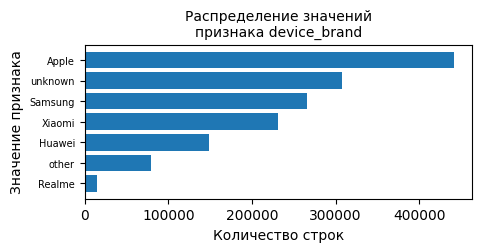

In [87]:
plot_feature_barh(df_train['device_brand'], size=(5, 2))

Смотрим распределение конверсии.

In [88]:
conv_distr(df_train, 'device_brand')

,conv_rate_%,sessions_count
device_brand,,
unknown,3.11,307255
Samsung,3.01,265835
Apple,2.63,441303
Huawei,2.43,148475
other,2.33,78854
Xiaomi,2.28,231129
Realme,2.23,15182


Различия в конверсии между брендами устройств невелики (2.23–3.11%), что указывает на низкую информативность признака.

#### 1.4.5.11 Признак `device_screen_resolution`

In [89]:
resolution_vc = df_train['device_screen_resolution'].value_counts()
one_count_values_share = (
    100 * resolution_vc[resolution_vc==1].count() / len(resolution_vc)
)
print(f'Количество уникальных значений: {resolution_vc.count()}\n'
      f'Доля значений, встречающихся один раз: {one_count_values_share:.1f} %')

Количество уникальных значений: 4492
Доля значений, встречающихся один раз: 50.7 %


Признак содержит около 4500 уникальных значений, что для категориального признака является очень высокой кардинальностью. Половина значений встречается только один раз. Использовать этот признак как категориальный невозможно — количество уникальных значений чрезмерно велико. В исходном виде признак непригоден для прямого кодирования через OHE и требует преобразования. Посмотрим на значения признака.

In [90]:
df_train['device_screen_resolution'].head()

1368913    1920x1080
201023       360x760
148484     2560x1440
1795167     1536x864
1493778    1680x1050
Name: device_screen_resolution, dtype: object

Проверим, во всех ли строках такой формат значения.

In [91]:
x_mask = df_train['device_screen_resolution'].str.contains('x', na=False)
df_train.loc[~x_mask, ['device_screen_resolution']]

,device_screen_resolution
130171,(not set)
291016,(not set)
210759,(not set)
229786,(not set)
470835,(not set)
354463,(not set)
1202981,(not set)


В датасете есть значения device_screen_resolution, из которых нельзя извлечь целые числа. В остальных записях разделим текстовую колонку с разрешением на две целочисленные — `screen_width` и `screen_height`.

In [92]:
df_train.loc[x_mask, ['screen_width', 'screen_height']] = (
    df_train.loc[x_mask, 'device_screen_resolution']
        .str.split('x', expand=True)
        .astype(int)
        .to_numpy()
)
df_train = (
    df_train.drop(columns='device_screen_resolution')
)

Добавим две новые характеристики экрана - `screen_ratio` и `screen_pixels`.

In [93]:
width = df_train['screen_width']
height = df_train['screen_height']

df_train['screen_ratio'] = width / height
df_train['screen_pixels'] = width * height

Проверим наличие нереальных значений.

In [94]:
screen_ratio = df_train['screen_width'] / df_train['screen_height']
bad_scr_data_mask = (
    (df_train['screen_height'] < 300) |
    (df_train['screen_height'] > 4000) |
    (df_train['screen_width'] < 300) |
    (df_train['screen_width'] > 6000) |
    (df_train['screen_ratio'].isna()) |
    (df_train['screen_ratio'] < 0.44) |
    (df_train['screen_ratio'] > 3.6)
)
print(f'Количество записей с нереальным экраном: {bad_scr_data_mask.sum()}')

Количество записей с нереальным экраном: 5029


Посмотрим на распределение значений признака `screen_ratio`.

Количество квадратных экранов: 9548



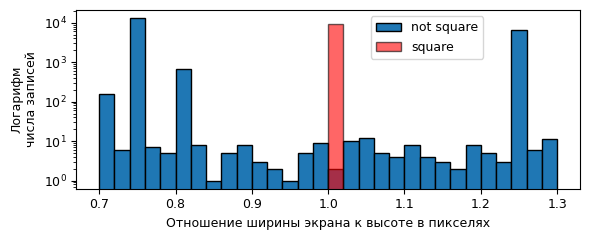

In [95]:
# Распределение записей по отношению ширины к высоте экрана в пикселях

ratio = df_train['screen_ratio']
square_mask = ratio == 1
print(f'Количество квадратных экранов: {square_mask.sum()}\n')
bins = np.linspace(0.7, 1.3, 31)
with plt.rc_context({'font.size': 9}):
    plt.figure(figsize=(6, 2.5))
    plt.yscale('log')
    plt.hist(ratio[~square_mask], bins=bins, edgecolor='k', label='not square')
    plt.hist(ratio[square_mask], bins=bins, edgecolor='k', label='square',
             alpha=0.6, color='r')
    plt.xlabel('Отношение ширины экрана к высоте в пикселях')
    plt.ylabel('Логарифм\nчисла записей')
    plt.legend(loc='upper right', bbox_to_anchor=(0.82, 1))

plt.tight_layout()

Проверим есть ли целевые сессии с квадратными экранами.

In [96]:
print(f' Количество целевых сессий с квадратным экраном: '
      f'{df_train.loc[square_mask, 'target'].sum()}')

 Количество целевых сессий с квадратным экраном: 0


In [97]:
square_resolutions = df_train.loc[
    square_mask, ['screen_width', 'screen_height']
].value_counts()
square_resolutions

screen_width  screen_height
2000.0        2000.0           9498
1366.0        1366.0             28
1024.0        1024.0             17
320.0         320.0               3
360.0         360.0               1
1080.0        1080.0              1
Name: count, dtype: int64

In [98]:
print(f'{100 * square_resolutions.iloc[0] / square_mask.sum():.1f} %'
      f' квадратных экранов имеют разрешение 2000х2000')

99.5 % квадратных экранов имеют разрешение 2000х2000


Разрешение 2000×2000 не существует в реальных устройствах. Дополним маску `bad_scr_data_mask`.

In [99]:
bad_square_mask = (df_train['screen_width']==2000) & (df_train['screen_height']==2000)
bad_scr_data_mask = bad_scr_data_mask | bad_square_mask

Заменим размеры неадекватных экранов на медианные значения.

In [100]:
width_mode, height_mode = (
    df_train[['screen_width', 'screen_height']].value_counts().idxmax()
)
df_train.loc[bad_scr_data_mask, 'screen_width'] = width_mode
df_train.loc[bad_scr_data_mask, 'screen_height'] = height_mode
df_train.loc[bad_scr_data_mask, 'screen_ratio'] = width_mode / height_mode
df_train.loc[bad_scr_data_mask, 'screen_pixels'] = width_mode * height_mode
# пометим изначально неадекватные экраны
df_train['screen_bad_data'] = bad_scr_data_mask

Убедимся, что пустых значений не осталось.

In [101]:
df_train[['screen_width', 'screen_height']].isna().any()

screen_width     False
screen_height    False
dtype: bool

Ранее из-за наличия NaN в параметрах экрана целочисленные значения автоматически преобразовались в тип float.

In [102]:
df_train.filter(like='screen').dtypes

screen_width       float64
screen_height      float64
screen_ratio       float64
screen_pixels      float64
screen_bad_data       bool
dtype: object

Теперь, когда NaN уже нет, приведём размеры экрана и количество пикселей к целочисленному типу.

In [103]:
df_train['screen_width'] = df_train['screen_width'].astype(int)
df_train['screen_height'] = df_train['screen_height'].astype(int)
df_train['screen_pixels'] = df_train['screen_pixels'].astype(int)
df_train.filter(like='screen').dtypes

screen_width         int32
screen_height        int32
screen_ratio       float64
screen_pixels        int32
screen_bad_data       bool
dtype: object

Рассчитаем коэффициенты корреляции Пирсона между целевой переменной и параметрами экрана.

In [104]:
df_train.filter(regex='screen|target').corr().iloc[[0], 1:]

,screen_width,screen_height,screen_ratio,screen_pixels,screen_bad_data
target,0.010475,0.017432,0.004229,0.010792,-0.010994


Значения коэффициентов корреляции близки к нулю, что указывает на отсутствие линейной корреляции между параметрами экрана и вероятностью совершения целевого действия. Рассмотрим точечные диаграммы параметров экрана для целевых и нецелевых сессий.

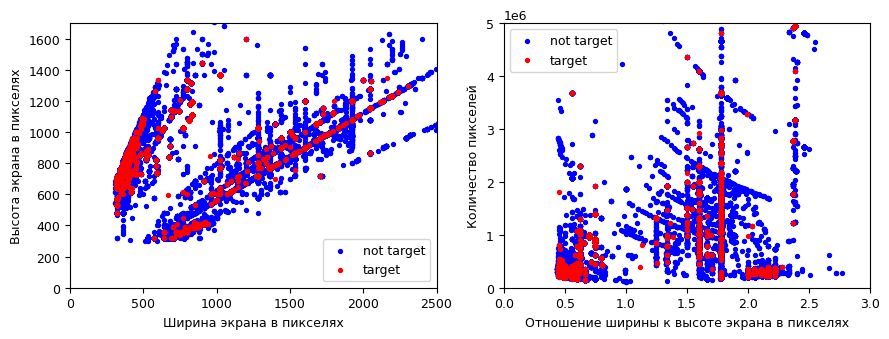

In [105]:
# Точечные диаграммы параметров экрана для целевых и нецелевых сессий

screen_width = df_train['screen_width']
screen_height = df_train['screen_height']
screen_ratio = df_train['screen_ratio']
screen_pixels = df_train['screen_pixels']
target_mask = df_train['target'] == 1
    
with plt.rc_context({'font.size': 9}):
    fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(9, 3.5))
    
    # Размеры экрана
    ax1.scatter(screen_width[~target_mask],
                screen_height[~target_mask],
                c='b', s=8, label='not target')
    ax1.scatter(screen_width[target_mask],
                screen_height[target_mask],
                c='r', s=8, label='target')
    ax1.set_xlabel('Ширина экрана в пикселях')
    ax1.set_ylabel('Высота экрана в пикселях')
    ax1.set_xlim(0, 2500)
    ax1.set_ylim(0, 1700)
    ax1.legend(loc='lower right')
    
    # Отношение сторон и количество пикселей
    ax2.scatter(screen_ratio[~target_mask],
                screen_pixels[~target_mask],
                c='b', s=8, label='not target')
    ax2.scatter(screen_ratio[target_mask],
                screen_pixels[target_mask],
                c='r', s=8, label='target')
    ax2.set_xlabel('Отношение ширины к высоте экрана в пикселях')
    ax2.set_ylabel('Количество пикселей')
    ax2.set_xlim(0, 3)
    ax2.set_ylim(0, 5000000)
    ax2.legend(loc='upper left')
    
plt.tight_layout()

Распределения целевых и нецелевых точек визуально отличаются. Несмотря на отсутствие линейной корреляции, возможно наличие нелинейной связи параметров экрана с целевым действием. Рассмотрим гистограммы каждого параметра отдельно.

In [106]:
# Функция для наложения двух гистограмм для целевых и нецелевых сессий

def plot_hist_overlay(ax, low, high, data, mask, legend_loc='upper right'):
    bins = np.linspace(low, high, 21)
    ax.hist(data[~mask], bins=bins, density=True, color='b',
            alpha=1, edgecolor='k', label='not target')
    ax.hist(data[mask], bins=bins, density=True, color='r',
            alpha=0.6, edgecolor='k', label='target')
    range_share = 100 * ((low <= data) & (data <= high)).mean()
    ax.set_title(f'В диапазоне {low} — {high}\n'
                 f'находится {range_share:.0f} % всех значений')
    ax.set_ylabel('Плотность\nраспределения')
    ax.legend(loc=legend_loc)

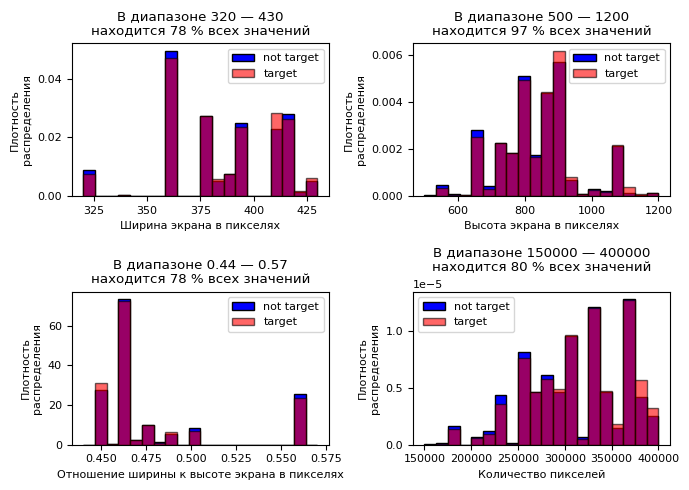

In [107]:
# Гистограммы распределений параметров экрана для целевых и нецелевых сессий

with plt.rc_context({'font.size': 8}):
    fig, ((ax1, ax2),
          (ax3, ax4)) = plt.subplots(nrows=2, ncols=2, figsize=(7, 5))
    
    plot_hist_overlay(ax1, 320, 430, screen_width, target_mask)
    plot_hist_overlay(ax2, 500, 1200, screen_height, target_mask)
    plot_hist_overlay(ax3, 0.44, 0.57, screen_ratio, target_mask)
    plot_hist_overlay(ax4, 150000, 400000, screen_pixels, target_mask,
                      legend_loc='upper left')
    
    ax1.set_xlabel('Ширина экрана в пикселях')
    ax2.set_xlabel('Высота экрана в пикселях')
    ax3.set_xlabel('Отношение ширины к высоте экрана в пикселях')
    ax4.set_xlabel('Количество пикселей')

plt.tight_layout()

Визуально не видно явных различий между распределениями. Влияние этих признаков на качество предсказания оценим при обучении моделей.

#### 1.4.5.12 Признак `device_browser`

Смотрим категории с численностью не менее 1% от всех записей.

In [108]:
device_browser_top_freq = top_freq_cats(df_train['device_browser'])
device_browser_top_freq

,count,share
device_browser,,
Chrome,810619,0.5448
Safari,383054,0.2574
YaBrowser,106576,0.0716
Safari (in-app),55898,0.0376
Android Webview,44445,0.0299
Samsung Internet,37934,0.0255
Opera,21434,0.0144


Объединим редкие категрии и посмотрим на распределение значений признака.

In [109]:
rare_to_other(df_train, 'device_browser', device_browser_top_freq)

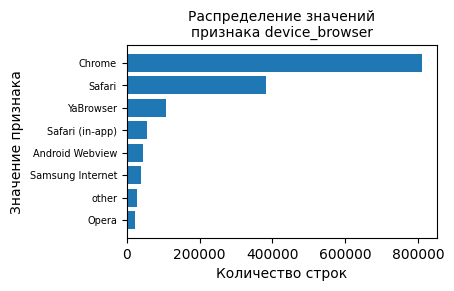

In [110]:
plot_feature_barh(df_train['device_browser'], size=(4, 2.5))

Смотрим распределение конверсии.

In [111]:
conv_distr(df_train, 'device_browser')

,conv_rate_%,sessions_count
device_browser,,
other,3.13,28073
YaBrowser,3.05,106576
Android Webview,2.79,44445
Safari,2.79,383054
Chrome,2.69,810619
Samsung Internet,2.56,37934
Opera,2.09,21434
Safari (in-app),1.77,55898


Различия в конверсии между основными браузерами невелики (1.77–3.13%), при этом основная часть наблюдений сосредоточена в категориях `Chrome` и `Safari` с близкими значениями конверсии, что указывает на низкую информативность признака.

При этом категории встроенных браузеров (Android Webview, Safari (in-app)) не демонстрируют повышенной конверсии по сравнению с основными браузерами. Это указывает на то, что сам по себе факт использования встроенного браузера не является определяющим фактором высокой вероятности целевого действия. Следовательно, повышенная конверсия категории `device_os = unknown` связана не со всем in-app трафиком в целом, а преимущественно с подмножеством переходов, формируемых из уведомлений, сообщений и внутренних ссылок приложений, характеризующихся более высоким намерением пользователя.

#### 1.4.5.13 Признак `geo_country`

In [112]:
geo_country = df_train['geo_country']
print(f'Количество уникальных значений: {geo_country.nunique()}')
geo_country_vc = geo_country.value_counts(normalize=True)
pd.DataFrame({
    'counts': geo_country_vc,
    'share_%': (100 * geo_country_vc).round(2)
}).head(10)

Количество уникальных значений: 164


,counts,share_%
geo_country,,
Russia,0.968061,96.81
United States,0.006320,0.63
Ukraine,0.004860,0.49
Ireland,0.002169,0.22
Belarus,0.001954,0.20
Sweden,0.001444,0.14
Kazakhstan,0.001234,0.12
Germany,0.001178,0.12
Turkey,0.001067,0.11


Почти все пользователи (≈96.8 %) приходят из России, что соответствует описанию сервиса. Остальные страны встречаются редко — каждая меньше 1 %, объединим их в одну категорию `other`. Среди прочих, в категорию `other` попадёт значение `(not set)`, поэтому его замена на `unknown` не требуется.

Как у остальных признаков определим категории с численностью не менее 1% от всех записей.

In [113]:
geo_country_top_freq = top_freq_cats(df_train['geo_country'])
geo_country_top_freq

,count,share
geo_country,,
Russia,1440506,0.9681


Объединим редкие страны и посмотрим на распределение значений признака.

In [114]:
rare_to_other(df_train, 'geo_country', geo_country_top_freq)

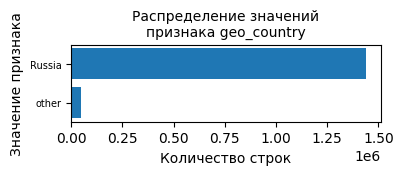

In [115]:
plot_feature_barh(df_train['geo_country'], size=(4, 1))

Смотрим распределение конверсии.

In [116]:
conv_distr(df_train, 'geo_country')

,conv_rate_%,sessions_count
geo_country,,
Russia,2.73,1440506
other,1.93,47527


Несмотря на наличие различий в конверсии между категориями (1.93–2.73%), доминирование одной страны и агрегированный характер категории `other` указывают на ограниченную информативность признака `geo_country`.

#### 1.4.5.14 Признак `geo_city`

В соответствии с принятым ранее решением, заменяем значени `(not set)` на `unknown`.

In [117]:
not_set_to_unknown(df_train, 'geo_city')

Количество замен (not set) -> unknown: 62438


Смотрим категории с численностью не менее 1% от всех записей.

In [118]:
geo_city_top_freq = top_freq_cats(df_train['geo_city'])
geo_city_top_freq

,count,share
geo_city,,
Moscow,644537,0.4331
Saint Petersburg,237363,0.1595
unknown,62438,0.0420
Yekaterinburg,28592,0.0192
Krasnodar,25639,0.0172
Kazan,23585,0.0158
Samara,20056,0.0135
Nizhny Novgorod,17695,0.0119
Ufa,17280,0.0116


Объединим редкие города и посмотрим на распределение значений признака.

In [119]:
rare_to_other(df_train, 'geo_city', geo_city_top_freq)

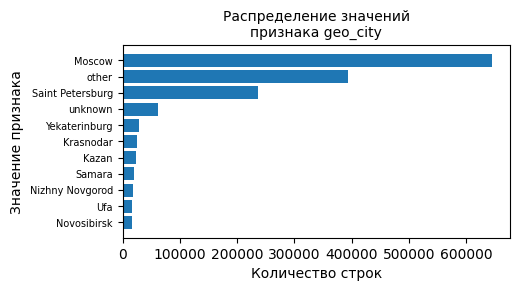

In [120]:
plot_feature_barh(df_train['geo_city'], size=(5, 2.5))

Посмотрим на распределение конверсии.

In [121]:
conv_distr(df_train, 'geo_city').head(50)

,conv_rate_%,sessions_count
geo_city,,
Kazan,3.97,23585
Krasnodar,3.28,25639
Ufa,3.00,17280
Samara,2.95,20056
Moscow,2.93,644537
other,2.54,393634
Nizhny Novgorod,2.43,17695
Yekaterinburg,2.43,28592
Saint Petersburg,2.41,237363


Различия в конверсии между городами (2.00–3.97%) при значительных объёмах наблюдений у основных категорий указывают на информативность признака `geo_city`.

#### 1.4.5.15 Обобщённые выводы по информативности признаков

Проведённый анализ показал существенные различия в информативности признаков различных групп. Наиболее высокую информативность демонстрируют UTM-признаки (`utm_source`, `utm_campaign`, `utm_medium`, `utm_adcontent`), а также признак `geo_city`, характеризующиеся устойчивыми различиями в конверсии между категориями при значительных объёмах наблюдений. Данные признаки отражают особенности источников трафика, маркетинговых кампаний и регионального поведения пользователей и являются основными предикторами высокой вероятности целевого действия.

Умеренную информативность демонстрируют признаки `device_os` и `utm_keyword`. В частности, повышенная конверсия категории `device_os = unknown` связана не с типом операционной системы как таковым, а с особенностями контекста перехода.

Технические и аппаратные признаки (`device_category`, `device_brand`, `device_browser`), а также признак `geo_country`, демонстрируют ограниченную информативность. Для данных признаков характерны небольшой разброс значений конверсии, доминирование отдельных категорий и агрегированный характер значений, что существенно ограничивает их вклад в разделение выборки.

В целом, наибольший вклад в объяснение вероятности целевого действия вносят признаки, отражающие источник и контекст привлечения пользователя, а также региональные особенности поведения, тогда как аппаратные и технические характеристики устройств оказываются вторичными факторами.

### 1.4.6 Feature engineering

#### 1.4.6.1 Стандартизация числовых признаков

Осмотрим типы данных всех признаков.

In [122]:
df_train.dtypes

utm_source          object
utm_medium          object
utm_campaign        object
utm_adcontent       object
utm_keyword         object
device_category     object
device_os           object
device_brand        object
device_browser      object
geo_country         object
geo_city            object
target               int32
screen_width         int32
screen_height        int32
screen_ratio       float64
screen_pixels        int32
screen_bad_data       bool
dtype: object

Осуществляем стандартизацию числовых признаков.

In [123]:
numeric_df_part = (df_train.select_dtypes(include=['number'])
                   .drop(columns='target'))
numeric_features = numeric_df_part.columns
numeric_features_std = [f + '_std' for f in numeric_features]

std_scaler = StandardScaler()
numeric_df_part_std = std_scaler.fit_transform(numeric_df_part)
df_train[numeric_features_std] = numeric_df_part_std
df_train = df_train.drop(columns=numeric_features)

Проверяем результат стандартизации.

In [124]:
df_train.filter(like='screen').head()

,screen_bad_data,screen_width_std,screen_height_std,screen_ratio_std,screen_pixels_std
1368913,False,2.348070,1.621565,1.929579,2.294694
201023,False,-0.527835,-0.483360,-0.525031,-0.483461
148484,False,3.527929,3.989606,1.929579,4.783920
1795167,False,1.640155,0.200740,1.929579,1.142538
1493778,False,1.905623,1.424228,1.594960,1.816851


#### 1.4.6.2 One-Hot Encoding

In [125]:
# Это нужно чтобы позже сравнить датафреймы в 2.4
df_train = df_train.replace('other', 'infrequent_sklearn')

In [126]:
categorial_df = df_train.select_dtypes(include='object')

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
ohe_array = ohe.fit_transform(categorial_df)
ohe_feature_names = ohe.get_feature_names_out()
categorial_df_ohe = pd.DataFrame(
    ohe_array.astype('int8'),
    columns=ohe_feature_names,
    index=categorial_df.index
)
df_train = pd.concat(
    [df_train, categorial_df_ohe], axis=1
)
df_train = df_train.drop(columns=categorial_df.columns)

Проверяем результат One-Hot-кодирования

In [127]:
df_train.head()

,target,screen_bad_data,screen_width_std,screen_height_std,screen_ratio_std,screen_pixels_std,utm_source_BHcvLfOaCWvWTykYqHVe,utm_source_MvfHsxITijuriZxsqZqt,utm_source_PlbkrSYoHuZBWfYjYnfw,utm_source_QxAxdyPLuQMEcrdZWdWb,...,geo_city_Krasnodar,geo_city_Moscow,geo_city_Nizhny Novgorod,geo_city_Novosibirsk,geo_city_Saint Petersburg,geo_city_Samara,geo_city_Ufa,geo_city_Yekaterinburg,geo_city_infrequent_sklearn,geo_city_unknown
1368913,0,False,2.348070,1.621565,1.929579,2.294694,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
201023,0,False,-0.527835,-0.483360,-0.525031,-0.483461,0,1,0,0,...,0,0,0,0,1,0,0,0,0,0
148484,0,False,3.527929,3.989606,1.929579,4.783920,1,0,0,0,...,0,1,0,0,0,0,0,0,0,0
1795167,0,False,1.640155,0.200740,1.929579,1.142538,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1493778,0,False,1.905623,1.424228,1.594960,1.816851,1,0,0,0,...,0,1,0,0,0,0,0,0,0,0


### 1.4.7 Итоги обработки

Вычисляем продолжительность подготовки данных.

In [128]:
prep_duration = format_duration(time.time() - start_prep)

Сохраняем данные в файлы.

In [129]:
start_save2 = time.time()
df_train.to_pickle('./data/processed/df_train.pkl')
df_train_raw.to_pickle('./data/processed/df_train_raw.pkl')
df_test_raw.to_pickle('./data/processed/df_test_raw.pkl')
save2_duration = format_duration(time.time() - start_save2)

Подводим итоги по машинному времени.

In [130]:
print('ПОДГОТОВКА ОБУЧАЮЩИХ ДАННЫХ:')

try: start_read
except NameError:
    total_prep_duration = format_duration(time.time() - start_read_labeled)
else:
    total_prep_duration = format_duration(time.time() - start_read)
    print('• Считывание исходных файлов:', read_duration,
          '\n• Агрегация событий:', aggreg_duration,
          '\n• Сохранение сессий с target:', save1_duration)

print('• Считывание сессий с target:', read_labeled_duration,
      '\n• Обработка и визуализация:', prep_duration,
      '\n• Сохранение данных в файлы:', save2_duration,
      '\n\nИТОГО:', total_prep_duration)

ПОДГОТОВКА ОБУЧАЮЩИХ ДАННЫХ:
• Считывание исходных файлов: 2.2 мин. 
• Агрегация событий: 37.6 сек. 
• Сохранение сессий с target: 7.0 сек.
• Считывание сессий с target: 2.0 сек. 
• Обработка и визуализация: 1.1 мин. 
• Сохранение данных в файлы: 9.3 сек. 

ИТОГО: 4.2 мин.


In [131]:
print('Размеры подготовленного датафрейма:', df_train.shape)

Размеры подготовленного датафрейма: (1488033, 87)


## 1.5 Дополнительный EDA (не влияет на подготовку данных)

#### 1.5.1 Анализ динамики во времени

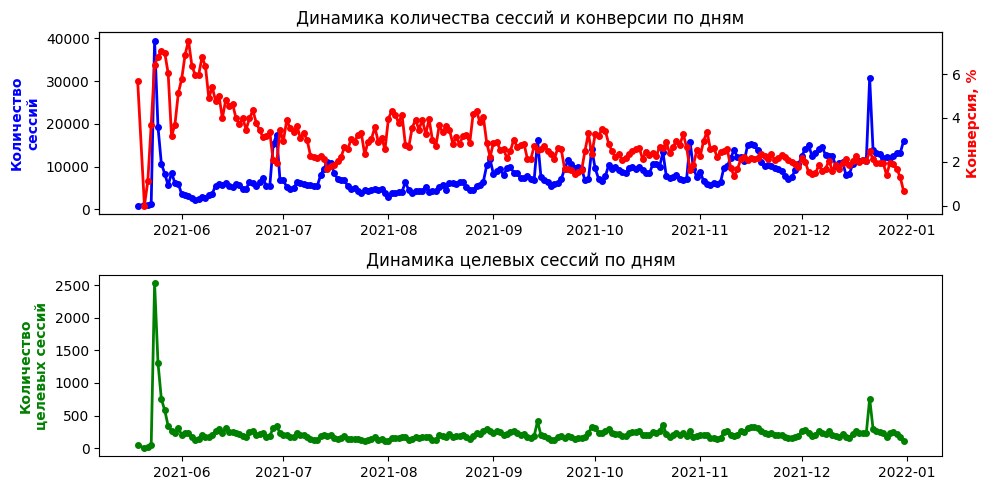

In [132]:
# Графики общего количества сессий, конверсии и числа целевых сессий по дням

df = sessions_target[['visit_date', 'visit_time', 'target']]
date_conv_distr = conv_distr(df, 'visit_date').sort_index()
fig, (ax1, ax3) = plt.subplots(nrows=2, ncols=1, figsize=(10, 5))

ax1.set_title('Динамика количества сессий и конверсии по дням')
ax1.set_ylabel('Количество\nсессий', c='b', fontweight='bold')
ax1.plot(date_conv_distr['sessions_count'],
         c='b', linewidth = 2, marker='o', markersize=4)
ax2 = ax1.twinx()
ax2.set_ylabel('Конверсия, %', c='r', fontweight='bold')
ax2.plot(date_conv_distr['conv_rate_%'],
         c='r', linewidth = 2, marker='o', markersize=4)

ax3.set_title('Динамика целевых сессий по дням')
ax3.set_ylabel('Количество\nцелевых сессий', c='g', fontweight='bold')
ax3.plot(df.groupby('visit_date')['target'].sum().sort_index(),
         c='g', linewidth = 2, marker='o', markersize=4)

plt.tight_layout()

За исключением двух явно выбивающихся дней данные однородны, значения одного порядка. Дат с нулевыми значениями нет, что косвенно подтверждает корректность сбора данных. На всём периоде заметны два медленных тренда — постепенный рост общего количества сессий и плавное снижение конверсии. Эти изменения компенсируют друг друга, поэтому количество целевых действий в день остаётся относительно стабильным. Видно два выраженных выброса — в конце мая и в декабре. Оба представляют собой резкое увеличение трафика, однако ведут себя по-разному — майский всплеск сопровождается конверсией выше среднего, а декабрьский происходит при обычных значениях конверсии. Подобные сочетания — резкий рост сессий одновременно с сохранением или повышением конверсии — трудно объяснить случайным колебанием поведения пользователей. Наиболее правдоподобное объяснение — влияние внешних факторов, таких как краткосрочные рекламные активности. В остальном данные выглядят реалистично и характерно для реальной работы сайта. Посмотрим на распределения по дням недели и времени суток.

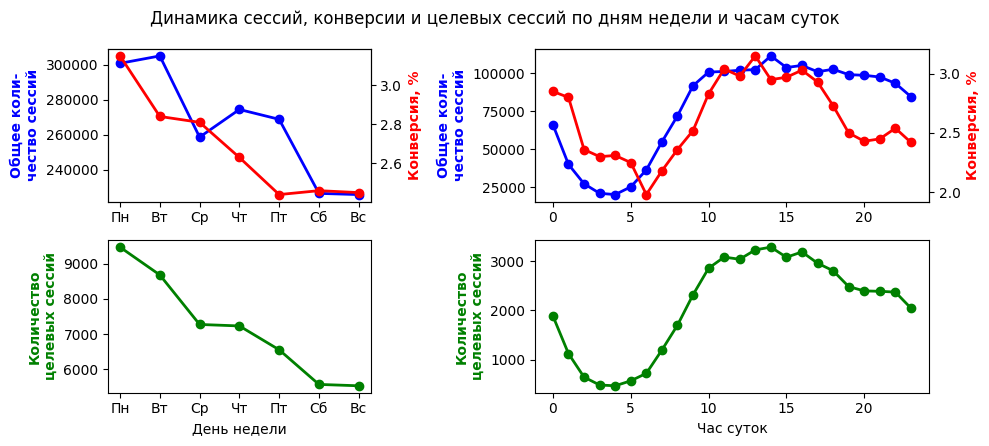

In [133]:
# Графики общего количества сессий, конверсии и числа целевых сессий по дням недели и часам суток

df = sessions_target[['visit_date', 'visit_time', 'target']].copy()
df['weekday'] = df['visit_date'].apply(lambda t: t.weekday())
df['hour'] = df['visit_time'].apply(lambda t: t.hour)
weekday_conv_distr = conv_distr(df, 'weekday').sort_index()
hour_conv_distr = conv_distr(df, 'hour').sort_index()
weekday_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']

fig, ((ax1, ax3),
      (ax5, ax6)) = plt.subplots(nrows=2, ncols=2, figsize=(10, 4.5),
                                 gridspec_kw={'width_ratios': [1, 1.5]})

plt.suptitle('Динамика сессий, конверсии и целевых'
             ' сессий по дням недели и часам суток')

ax1.set_ylabel('Общее коли-\nчество сессий', c='b', fontweight='bold')
ax1.plot(weekday_names, weekday_conv_distr['sessions_count'],
         c='b', linewidth=2, marker='o', markersize=6)
ax2 = ax1.twinx()
ax2.set_ylabel('Конверсия, %', c='r', fontweight='bold')
ax2.plot(weekday_conv_distr['conv_rate_%'],
         c='r', linewidth=2, marker='o', markersize=6)

ax3.set_ylabel('Общее коли-\nчество сессий', c='b', fontweight='bold')
ax3.plot(hour_conv_distr['sessions_count'],
         c='b', linewidth=2, marker='o', markersize=6)
ax4 = ax3.twinx()
ax4.set_ylabel('Конверсия, %', c='r', fontweight='bold')
ax4.plot(hour_conv_distr['conv_rate_%'],
         c='r', linewidth=2, marker='o', markersize=6)

ax5.set_xlabel('День недели')
ax5.set_ylabel('Количество\nцелевых сессий', c='g', fontweight='bold')
ax5.plot(weekday_names, df.groupby('weekday')['target'].sum().sort_index(),
         c='g', linewidth=2, marker='o', markersize=6)

ax6.set_xlabel('Час суток')
ax6.set_ylabel('Количество\nцелевых сессий', c='g', fontweight='bold')
ax6.plot(df.groupby('hour')['target'].sum().sort_index(),
         c='g', linewidth=2, marker='o', markersize=6)

plt.tight_layout()

Распределение по дням недели показывает типичную для веб-трафика структуру: наибольшая активность и лучшая конверсия наблюдаются в начале недели. Понедельник является наиболее продуктивным днём: при высокой посещаемости (≈300 тыс. сессий) фиксируется максимальная конверсия — около 3.2%, что приводит к наибольшему числу целевых действий. Начиная со вторника, коэффициент конверсии постепенно снижается до минимальных значений в выходные (≈2.5%), что сопровождается уменьшением общего трафика и числа целевых действий.<br>
Распределение по часам показывает чёткую суточную структуру активности. Минимальные значения трафика и конверсии наблюдаются ночью (0–5 часов). Начиная с 9 утра качество трафика значительно улучшается, и в течение рабочего дня (10–17 часов) фиксируются максимальные значения конверсии — около 3%. Этот интервал даёт основную часть целевых действий. Вечером конверсия постепенно снижается, хотя трафик остаётся высоким. Общая динамика выглядит естественно.

#### 1.5.2 EDA-признак `eda_is_social`

Теперь используем информацию о кодировке признака `utm_source` из методических указаний к работе. Создадим признак `is_social`, который будет равен единице в случаях, когда пользователь пришёл из соцсетей, в остальных случаях - нулю. Берём исходные значения признака и формируем на их основе EDA-признак в отдельном датафрейме.

In [134]:
df = sessions_target[['utm_source', 'target']].copy()
df['eda_is_social'] = df['utm_source'].isin(
    ['QxAxdyPLuQMEcrdZWdWb', 'MvfHsxITijuriZxsqZqt', 'ISrKoXQCxqqYvAZICvjs',
     'IZEXUFLARCUMynmHNBGo', 'PlbkrSYoHuZBWfYjYnfw', 'gVRrcxiDQubJiljoTbGm']
)

Посмотрим, какую долю из всех сессий составляют соцсетевые.

In [135]:
print(f'Доля соцсетевых сессий: {100 * df['eda_is_social'].mean():.1f} %')

Доля соцсетевых сессий: 14.7 %


Посмотрим на различия конерсии.

In [136]:
conv_distr(df, 'eda_is_social')

,conv_rate_%,sessions_count
eda_is_social,,
False,2.92,1585815
True,1.47,274227


Трафик из соцсетей составляет около 15%, а его конверсия примерно в два раза ниже, чем у остальных (1.5% против 2.9%). Это указывает на явно меньшую результативность такого трафика.

#### 1.5.3 EDA-признак `eda_traffic_paid`

Методические рекомендации к работе дают следующую информацию:<br>
"Органический трафик — все визиты с `ga_sessions.utm_medium` in (`'organic',
'referral', '(none)'`).<br>
Платный трафик — весь неорганический трафик."<br>
Это позволяет создать EDA-признак `eda_traffic_paid` на основе исходных значений признака `utm_medium`.

In [137]:
df = sessions_target[['utm_medium', 'target']].copy()
df['eda_traffic_paid'] = (
    np.where(df['utm_medium']
             .isin(['organic', 'referral', '(none)']), False, True)
)

Посмотрим, какую долю из всех сессий составляют платные.

In [138]:
print('Доля сессий с платным трафиком:',
      f'{100 * df['eda_traffic_paid'].mean():.1f} %')

Доля сессий с платным трафиком: 72.3 %


Посмотрим на различия конерсии.

In [139]:
conv_distr(df, 'eda_traffic_paid')

,conv_rate_%,sessions_count
eda_traffic_paid,,
False,4.04,515659
True,2.19,1344383


Платный трафик составляет около 72%, при этом его конверсия почти в два раза ниже, чем у органического. Это может показаться неожиданным, однако органический трафик включает брендовые поисковые запросы, прямые заходы и реферальные переходы — аудиторию, уже знакомую с продуктом и более мотивированную совершить целевое действие. Платный трафик, напротив, привлекает более широкий и менее целевой сегмент, что закономерно отражается в сниженной конверсии.

#### 1.5.4 Линейные корреляции

In [140]:
%%time
corr_matrix = df_train.corr()
corr_matrix[['target']].sort_values(by='target', ascending=False)[1:11]

CPU times: total: 11.7 s
Wall time: 11.7 s


,target
utm_campaign_LTuZkdKfxRGVceoWkVyg,0.049457
utm_medium_referral,0.049361
utm_adcontent_JNHcPlZPxEMWDnRiyoBf,0.044894
utm_source_bByPQxmDaMXgpHeypKSM,0.040888
device_os_unknown,0.037041
utm_keyword_unknown,0.036026
utm_source_aXQzDWsJuGXeBXexNHjc,0.024954
utm_medium_(none),0.021526
utm_source_fDLlAcSmythWSCVMvqvL,0.021526
screen_height_std,0.017432


Корреляционный анализ показывает, что наиболее заметно с целевым действием связаны UTM-параметры: отдельные кампании, источники и типы трафика дают корреляции порядка 0.03–0.05. Небольшие положительные связи также наблюдаются у `device_os_unknown` и `utm_keyword_unknown`, что, вероятно, отражает специфику каналов, где эти параметры часто не передаются. В целом значения корреляций невысокие, что естественно для one-hot признаков, при этом маркетинговые параметры остаются основными факторами, влияющими на вероятность совершения целевого действия.

#### 1.5.5 Рейтинг моделей автомобилей

Оценим популярность автомобилей по количеству успешно отправленных заявок (event_action = `'sub_submit_success'`).

In [141]:
calculate_ratings = True # можно выключить

In [142]:
# если старт с пункта 1.4, то считать hist и сформировать target_hit
if calculate_ratings:
    try: hits
    except NameError:
        start_read_hits = time.time()
        hits = pd.read_pickle('./data/raw/ga_hits.pkl')
        read_hits_duration = format_duration(time.time() - start_read_hits)
        print('Продолжительность считывания таблицы hits:', read_hits_duration)

        target_list = [
        'sub_car_claim_click', 'sub_car_claim_submit_click',
        'sub_open_dialog_click', 'sub_custom_question_submit_click',
        'sub_call_number_click', 'sub_callback_submit_click',
        'sub_submit_success', 'sub_car_request_submit_click'
        ]
        hits_target = hits[['hit_page_path', 'event_action']].copy()
        hits_target['target_hit'] = hits_target['event_action'].isin(target_list).astype(int)

In [143]:
if calculate_ratings:
    # Только в таких строках есть марка и модель автомобиля:
    mask_cars_all = hits['hit_page_path'].str.contains('/cars/all/')
    # Посмотрим, у каких автомобилей больше всего успешно отправленных заявок
    mask = mask_cars_all & (hits_target['event_action'] == 'sub_submit_success')
    hits_target_filtered = hits_target.loc[mask].copy()
    hits_target_filtered['brand_model'] = (
        hits_target_filtered['hit_page_path']
            .str.split('/')
            .str[3:5]
            .str.join(' ')
    )
    cars_submits = (hits_target_filtered
        .groupby('brand_model')[['target_hit']]
        .sum()
        .rename(columns={'target_hit': 'submit_success_count'})
        .sort_values(by='submit_success_count', ascending=False)
    )
    display(cars_submits.head(10))

,submit_success_count
brand_model,
skoda rapid,1313
lada-vaz vesta,1161
volkswagen polo,1002
kia rio,329
mercedes-benz e-klasse,282
toyota camry,268
skoda karoq,267
renault logan,201
skoda octavia,193


# 2 Modeling

## 2.1 Авторские функции

In [144]:
# ПОСЛЕ ИМПОРТОВ МОЖНО НАЧАТЬ ОТСЮДА
# Run Selected Sell and All Below

def validate(model, X, y, cv, n_jobs=-1, verbose=True):
    start = time.time()
    scores = cross_val_score(
        model, X, y, cv=cv,
        scoring='roc_auc',
        n_jobs=n_jobs,
    )
    score_mean = scores.mean()
    score_std = scores.std()
    end = time.time()
    if verbose:
        print(
            'Модель:',
            f'Pipeline with {type(model.named_steps["model"]).__name__}'
            if hasattr(model, 'steps')
            else type(model).__name__
        )
        print(f'Продолжительность валидации: {(end - start) / 60:.1f} мин')
        print(f'ROC-AUC mean: {score_mean:.4f}')
        print(f'ROC-AUC std:  {score_std:.4f}')
    return score_mean, score_std

In [145]:
def GridSearchCV_visualizer(grid_search, param=None, value=None, width=10, sort=True, head=None):
    
    gs_results = pd.DataFrame(grid_search.cv_results_['params'])
    gs_results['rank_test_score'] = grid_search.cv_results_['rank_test_score']
    gs_results['mean_test_score'] = grid_search.cv_results_['mean_test_score']
    gs_results['mean_fit_time'] = grid_search.cv_results_['mean_fit_time']
    if sort:
        gs_results = gs_results.sort_values(by='rank_test_score').reset_index(drop=True)
    else:
        gs_results = gs_results.reset_index(drop=True)
        
    gs_results = gs_results[:head]

    fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(width, 4))  
    title = ('Отсортированные р' if sort else 'Р') + 'езультаты GridSearchCV'
    
    ax1.plot(gs_results.index, gs_results.mean_test_score, marker='o', c='r', ms=8, zorder=1)
    ax1.set_ylabel('mean ROC-AUC', c='r', fontsize=10, fontweight='bold')
    ax1.set_xticklabels([])
 
    ax2.plot(gs_results.index, gs_results.mean_fit_time, marker='o', c='b', ms=8, zorder=1)
    ax2.set_xlabel('Индекс датафрейма gs_results', fontsize=10)
    ax2.set_ylabel('mean fit time', c='b', fontsize=10, fontweight='bold')

    if param is not None and value is not None:
        fp = gs_results[gs_results[param]==value] # fp - fixed param    
        ax1.scatter(fp.index, fp.mean_test_score, marker='o', c='yellow', s=15, zorder=2)
        ax2.scatter(fp.index, fp.mean_fit_time, marker='o', c='yellow', s=15, zorder=2)
        title += f'\n(жёлтые точки - это \'{param}\'={value})'

    ax1.set_title(title, fontsize=10)
    plt.show()
    return gs_results

## 2.2 Предварительная оценка качества

In [146]:
# Если стартуем с моделирования, то считать файлы
try:
    X_train_raw, X_train
except NameError:
    df_train_raw = pd.read_pickle('./data/processed/df_train_raw.pkl')
    df_train = pd.read_pickle('./data/processed/df_train.pkl')

Разделяем признаки и целевую переменную, инициализируем сплиттер и модели.

In [147]:
X_train_raw = df_train_raw.drop(columns='target')
X_train = df_train.drop(columns='target')
y_train = df_train['target']

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

lr = LogisticRegression(n_jobs=1, random_state=42)
rf = RandomForestClassifier(n_jobs=-1, random_state=42)
mlp = MLPClassifier(early_stopping=True, random_state=42)

Оценим качество моделей с гиперпараметрами по умолчанию.

In [148]:
lr_auc = validate(lr, X_train, y_train, skf)[0]

Модель: LogisticRegression
Продолжительность валидации: 0.2 мин
ROC-AUC mean: 0.6695
ROC-AUC std:  0.0011


In [149]:
rf_auc = validate(rf, X_train, y_train, skf)[0]

Модель: RandomForestClassifier
Продолжительность валидации: 1.1 мин
ROC-AUC mean: 0.6332
ROC-AUC std:  0.0007


In [150]:
mlp_auc = validate(mlp, X_train, y_train, skf)[0]

Модель: MLPClassifier
Продолжительность валидации: 0.5 мин
ROC-AUC mean: 0.6744
ROC-AUC std:  0.0016


Полученные результаты показывают, что даже без оптимизации гиперпараметров качество предсказаний в итоговом тесте может достигнуть требуемого заданием уровня (ROC-AUC ~ 0.65).

## 2.3 Влияние признака `device_screen_resolution` на качество модели

Удаляем все колонки с характеристиками экрана и снова оцениваем качество.

In [151]:
screen_columns = df_train.filter(like='screen').columns
X_train = X_train.drop(columns=screen_columns)

In [152]:
lr_auc_nores = validate(lr, X_train, y_train, skf)[0]

Модель: LogisticRegression
Продолжительность валидации: 0.1 мин
ROC-AUC mean: 0.6684
ROC-AUC std:  0.0014


In [153]:
rf_auc_nores = validate(rf, X_train, y_train, skf)[0]

Модель: RandomForestClassifier
Продолжительность валидации: 0.9 мин
ROC-AUC mean: 0.6635
ROC-AUC std:  0.0010


In [154]:
mlp_auc_nores = validate(mlp, X_train, y_train, skf)[0]

Модель: MLPClassifier
Продолжительность валидации: 0.4 мин
ROC-AUC mean: 0.6733
ROC-AUC std:  0.0007


In [155]:
# Формируем сравнительную таблицу

columns = pd.MultiIndex.from_product(
    [['ROC-AUC'], ['LR', 'RF', 'MLP']],
    names=['metric', 'model']
)
index = pd.Series(['used', 'not used', 'difference'], name='screen_params')
values = [[lr_auc, rf_auc, mlp_auc],
          [lr_auc_nores, rf_auc_nores, mlp_auc_nores],
          [lr_auc_nores - lr_auc,
           rf_auc_nores - rf_auc,
           mlp_auc_nores - mlp_auc]]
pd.DataFrame(values, columns=columns, index=index).style.format("{:.3f}")

Полученная таблица в совокупности с выводами EDA показывает, что признак `device_screen_resolution` не улучшает качество моделей: для логистической регрессии и MLP разница в ROC-AUC практически отсутствует, а для случайного леса удаление признака даже повышает качество. Принимаем окончательное решение — не использовать данный признак.

## 2.4 Разработка и тестирование пайплайна подготовки данных (preprocessor)

Приведённая выше предварительная оценка качества была выполнена не по всем правилам — ohe.fit_transform() был применён ко всему X_train и не переобучался в каждом фолде кросс-валидации. Чтобы это исправить нужен пайплайн. Исключение признака `device_screen_resolution` упрощает пайплайн подготовки данных (preprocessor).

In [156]:
def prepare_for_ohe_function(
    X, cols_to_keep, cols_to_replace_not_set
):
    X = X[cols_to_keep].copy()
    X = X.fillna('unknown')
    X = X.replace('', 'unknown')
    X[cols_to_replace_not_set] = (
        X[cols_to_replace_not_set]
        .replace('(not set)', 'unknown')
    )
    return X

def make_preprocessor(columns):
    cols_to_keep = [
        col for col in columns
        if col.startswith(('utm_', 'device_', 'geo_'))
        and col not in ('device_model',
                        'device_screen_resolution')
    ]
    cols_to_replace_not_set = [
        col for col in cols_to_keep
        if not col.startswith('utm_')
    ]
    prepare_for_ohe = FunctionTransformer(
        prepare_for_ohe_function,
        kw_args={
            'cols_to_keep': cols_to_keep,
            'cols_to_replace_not_set': cols_to_replace_not_set
        },
        validate=False
    )
    ohe = OneHotEncoder(
        min_frequency=0.01,
        handle_unknown='infrequent_if_exist',
        sparse_output=True
    )
    pipeline = Pipeline([
        ('prepare_for_ohe', prepare_for_ohe),
        ('ohe', ohe),
    ])
    return pipeline

preprocessor = make_preprocessor(X_train_raw.columns)

Ещё раз обработаем исходные данные, но теперь с помощью пайплайна. Проверим соответствие пайплайна распределённой по ноутбуку первичной обработке посрдеством сравнение итоговых датафреймов. На выходе из пайплайна получим ndarray, поэтому для сравнения с X_train потребуется сформировать датафрейм.

In [157]:
start_prep = time.time()
ohe_array = preprocessor.fit_transform(X_train_raw).toarray()
print('Продолжительность подготовки данных с помощью пайплайна:',
      f'{time.time() - start_prep:.1f} сек')

# формируем датафрейм для сравнения
ohe = preprocessor.named_steps['ohe']
feature_names = ohe.get_feature_names_out()
X_train_2 = pd.DataFrame(
    ohe_array.astype('int8'),
    columns=feature_names,
    index=X_train_raw.index
)

Продолжительность подготовки данных с помощью пайплайна: 10.0 сек


Теперь можно сравнить датафреймы.

In [158]:
try:
    assert_frame_equal(
        X_train.sort_index(axis=1),
        X_train_2.sort_index(axis=1)
    )
    print('Датафреймы полностью совпадают!')
except AssertionError as error:
    print(error)

Датафреймы полностью совпадают!


Отлично! Пайплайн подготовки данных готов, теперь можно объединять его с разными моделями и выполнять кросс-валидацию без утечки данных.

## 2.5 Оптимизация

### 2.5.1 LogisticRegression

Полноценная кросс-валидация с переобучением OHE на каждом фолде.

In [159]:
lr = LogisticRegression(n_jobs=1, random_state=42)
lr_pipe = Pipeline([
        ('preprocess', preprocessor),
        ('model', lr),
])
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
lr_default_auc_mean, lr_default_auc_std = (
    validate(lr_pipe, X_train_raw, y_train, skf)
)

Модель: Pipeline with LogisticRegression
Продолжительность валидации: 0.5 мин
ROC-AUC mean: 0.6684
ROC-AUC std:  0.0014


Малое значение ROC-AUC std (≈ 0.001) свидетельствует о стабильности модели относительно разбиения данных, что позволяет выполнять оптимизацию гиперпараметров на одном стратифицированном разбиении без существенной потери надёжности оценки качества. Приступим к оптимизации.

In [160]:
%%time

p_mf = 'preprocess__ohe__min_frequency'
m_C = 'model__C'
m_p = 'model__penalty'
m_s = 'model__solver'
m_t = 'model__tol'

mfs = [0.0001] # уже оптимальное, ниже описано
Cs = [0.01, 0.1, 1, 10, 100, 1000]

param_grid = [
    {p_mf: mfs, m_C: Cs, m_p: ["l2"], m_s: ["lbfgs"]},
    {p_mf: mfs, m_C: Cs, m_p: ["l2"], m_s: ["newton-cg"]},
    {p_mf: mfs, m_C: Cs, m_p: ["l2"], m_s: ["newton-cholesky"]},
    {p_mf: mfs, m_C: Cs, m_p: ["l2"], m_s: ["sag"], m_t: [1e-2]},
    {p_mf: mfs, m_C: Cs, m_p: ["l2"], m_s: ["saga"], m_t: [1e-2]},
    {p_mf: mfs, m_C: Cs, m_p: ["l1"], m_s: ["saga"], m_t: [1e-2]},
]
strat_split_1 = StratifiedShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
lr_pipe_gs = GridSearchCV(
    cv=strat_split_1,
    scoring='roc_auc',
    estimator=lr_pipe,
    param_grid=param_grid,
    verbose=3,
    n_jobs=-1,
    # если не хватает памяти, тогда:
    # n_jobs=1,
    # pre_dispatch=1
)
lr_pipe_gs.fit(X_train_raw, y_train)

Fitting 1 folds for each of 36 candidates, totalling 36 fits
CPU times: total: 5min 24s
Wall time: 7min 41s


,estimator,Pipeline(step...m_state=42))])
,param_grid,"[{'model__C': [0.01, 0.1, ...], 'model__penalty': ['l2'], 'model__solver': ['lbfgs'], 'preprocess__ohe__min_frequency': [0.0001]}, {'model__C': [0.01, 0.1, ...], 'model__penalty': ['l2'], 'model__solver': ['newton-cg'], 'preprocess__ohe__min_frequency': [0.0001]}, ...]"
,scoring,'roc_auc'
,n_jobs,-1
,refit,True
,cv,StratifiedShu...ain_size=None)
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,steps,"[('prepare_for_ohe', ...), ('ohe', ...)]"


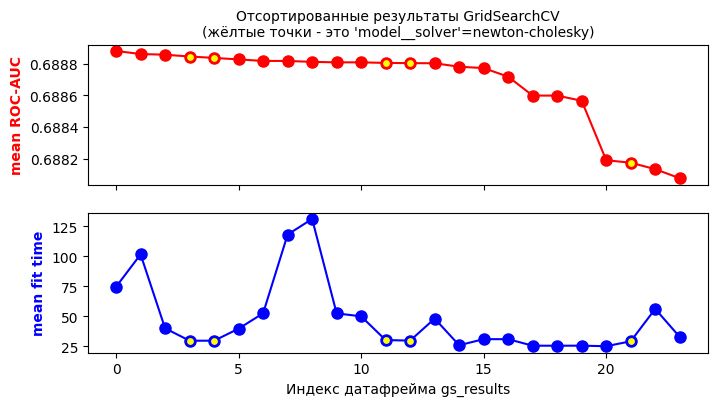

,model__C,model__penalty,model__solver,preprocess__ohe__min_frequency,model__tol,rank_test_score,mean_test_score,mean_fit_time
0,1.0,l1,saga,0.0001,0.01,1,0.688881,74.645124
1,10.0,l1,saga,0.0001,0.01,2,0.688862,101.661818
2,10.0,l2,sag,0.0001,0.01,3,0.688858,40.015783
3,1.0,l2,newton-cholesky,0.0001,NaN,4,0.688846,29.707205
4,10.0,l2,newton-cholesky,0.0001,NaN,5,0.688837,29.693469
5,10.0,l2,saga,0.0001,0.01,6,0.688828,39.726974


In [161]:
if hasattr(lr_pipe_gs, "cv_results_"):
    lr_pipe_gs_results = GridSearchCV_visualizer(
        lr_pipe_gs, m_s, 'newton-cholesky', width=8, head=24
    )
    display(lr_pipe_gs_results.head(6))

Лучшие конфигурации показали практически одинаковые значения ROC-AUC. В качестве финальной выбрана конфигурация с `solver='newton-cholesky'`, потому что при том же качестве она обучается значительно быстрее и является детерминированной. Поскольку более сильная регуляризация при том же качестве снижает риск переобучения выбираем меньшее значение `C=1`.

In [162]:
lr_pipe.set_params(
    preprocess__ohe__min_frequency=0.0001,
    model__C=1.0,
    model__penalty='l2',
    model__solver='newton-cholesky',
);

Для подбора оптимального значения `min_frequency` приведённый выше GridSearch выполнялся при различных значениях этого параметра. Для каждого значения оптимизировались остальные параметры и фиксировалось максимальное значение ROC-AUC. Результаты представлены на графике и в таблице.

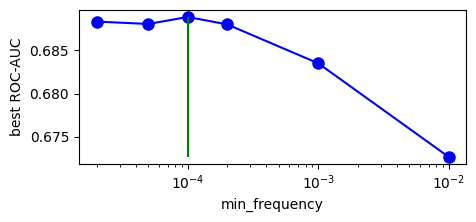

,best ROC-AUC
min_frequency,
0.00002,0.6883
0.00005,0.6881
0.00010,0.6889
0.00020,0.6880
0.00100,0.6835
0.01000,0.6727


In [163]:
# Формируем график и таблицу

columns = ['best ROC-AUC']
index = pd.Series(
    [0.01, 0.001, 0.0002, 0.0001, 0.00005, 0.00002], name='min_frequency'
)
values = [0.672670, 0.683517, 0.688026, 0.688881, 0.688074, 0.688345]

plt.figure(figsize=(5, 2))
plt.plot(index, values, c='b', marker='o', markersize=8)
plt.vlines(x=0.0001, ymin=0.672670, ymax=0.688881, color='g')
plt.xscale('log')
plt.xlabel('min_frequency')
plt.ylabel('best ROC-AUC')
plt.show()
values_rnd = [round(v, 4) for v in values]
pd.DataFrame(values_rnd, columns=columns, index=index).sort_index()

Рассмотрим гиперпараметр `class_weight`, который по умолчанию имеет значение `None`. Установка значения `class_weight='balanced'` может быть полезна при сильном дисбалансе классов. При выполнении полного перебора конфигураций с `class_weight='balanced'` у части конфигураций наблюдались проблемы со сходимостью. Поэтому влияние данного параметра оценим в формате ablation-проверки на оптимальной конфигурации модели, найденной при `class_weight=None`.

In [164]:
%%time

lr_pipe.set_params(model__class_weight='balanced')
lr_balanced_auc_mean = validate(lr_pipe, X_train_raw, y_train, skf, verbose=0)[0]

lr_pipe.set_params(model__class_weight=None)
lr_auc_mean, lr_auc_std = validate(lr_pipe, X_train_raw, y_train, skf, verbose=0)

CPU times: total: 35 s
Wall time: 1min 5s


In [165]:
columns = ['mean ROC-AUC']
index = pd.Series(['None', 'balanced', 'difference'], name='class_weight')
values = [lr_auc_mean, lr_balanced_auc_mean, lr_balanced_auc_mean - lr_auc_mean]
pd.DataFrame(values, columns=columns, index=index).style.format("{:.4f}")

,mean ROC-AUC
class_weight,
None,0.6858
balanced,0.6854
difference,-0.0004


Изменение значения параметра `class_weight` со значения по умолчанию `None` на `'balanced'` не повысило значение ROC-AUC. Посмотрим на итоговый результат оптимизации.

In [166]:
columns = pd.MultiIndex.from_product([['ROC-AUC'], ['mean', 'std']])
index = pd.Series(['default', 'optimized', 'difference'], name='LogisticRegression')
values = [[lr_default_auc_mean, lr_auc_mean, lr_auc_mean - lr_default_auc_mean],
          [lr_default_auc_std, lr_auc_std, lr_auc_std - lr_default_auc_std]]
pd.DataFrame(np.array(values).T, columns=columns, index=index).style.format("{:.4f}")

С помощью оптимизации удалось повысить ROC-AUC линейной регрессии на 0.0174, стабильность практически не изменилась.

### 2.5.2 RandomForestClassifier

In [167]:
print(preprocessor.get_params()['ohe__min_frequency'])

0.0001


In [168]:
preprocessor.set_params(ohe__min_frequency=0.01) # возвращаем исходное значение
to_dense32 = FunctionTransformer(
    lambda X: X.toarray().astype(np.float32), accept_sparse=True
)
rf = RandomForestClassifier(n_jobs=-1, random_state=42)
rf_pipe = Pipeline([
        ('preprocess', preprocessor),
        ('to_dense32', to_dense32), # без этого расчёт намного дольше
        ('model', rf),
])
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
rf_default_auc_mean, rf_default_auc_std = (
    validate(rf_pipe, X_train_raw, y_train, skf, n_jobs=1)
)

Модель: Pipeline with RandomForestClassifier
Продолжительность валидации: 1.3 мин
ROC-AUC mean: 0.6635
ROC-AUC std:  0.0010


Закомментированная сетка параметров `param_grid_all_tried` содержит все проверенные значения. Для экономии времени при демострации процесса оптимизации использована уменьшенная сетка параметров `param_grid_demo`.

In [169]:
%%time

# param_grid_all_tried = {
#     'preprocess__ohe__min_frequency': [0.02, 0.01, 0.001, 0.0001, 0.00005],
#     'model__min_samples_leaf': [2, 5, 10, 20,],
#     'model__max_depth': [None, 20, 40, 60, 80],
#     'model__max_samples': [0.25, 0.5, 0.75,]
#     'model__n_estimators': [100, 200, 400],
#     'model__max_features': ['sqrt', 'log2', 0.3],
#     'model__class_weight': [None ,'balanced'],
#     'model__bootstrap': [True, False],
# }

param_grid_demo = {
    'preprocess__ohe__min_frequency': [0.001, 0.0001],
    'model__min_samples_leaf': [5, 10],
    'model__max_samples': [0.25, 0.5],
    'model__n_estimators': [200],
    'model__max_depth': [60],
}

strat_split_1 = StratifiedShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
rf_pipe_gs = GridSearchCV(
    cv=strat_split_1,
    scoring='roc_auc',
    estimator=rf_pipe,
    param_grid=param_grid_demo,
    verbose=3,
    n_jobs=1,
)
rf_pipe_gs.fit(X_train_raw, y_train)

Fitting 1 folds for each of 8 candidates, totalling 8 fits
[CV 1/1] END model__max_depth=60, model__max_samples=0.25, model__min_samples_leaf=5, model__n_estimators=200, preprocess__ohe__min_frequency=0.001;, score=0.693 total time=  52.7s
[CV 1/1] END model__max_depth=60, model__max_samples=0.25, model__min_samples_leaf=5, model__n_estimators=200, preprocess__ohe__min_frequency=0.0001;, score=0.694 total time= 1.6min
[CV 1/1] END model__max_depth=60, model__max_samples=0.25, model__min_samples_leaf=10, model__n_estimators=200, preprocess__ohe__min_frequency=0.001;, score=0.693 total time=  51.5s
[CV 1/1] END model__max_depth=60, model__max_samples=0.25, model__min_samples_leaf=10, model__n_estimators=200, preprocess__ohe__min_frequency=0.0001;, score=0.694 total time= 1.5min
[CV 1/1] END model__max_depth=60, model__max_samples=0.5, model__min_samples_leaf=5, model__n_estimators=200, preprocess__ohe__min_frequency=0.001;, score=0.692 total time= 1.4min
[CV 1/1] END model__max_depth=60,

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__max_depth': [60], 'model__max_samples': [0.25, 0.5], 'model__min_samples_leaf': [5, 10], 'model__n_estimators': [200], ...}"
,scoring,'roc_auc'
,n_jobs,1
,refit,True
,cv,StratifiedShu...ain_size=None)
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,steps,"[('prepare_for_ohe', ...), ('ohe', ...)]"


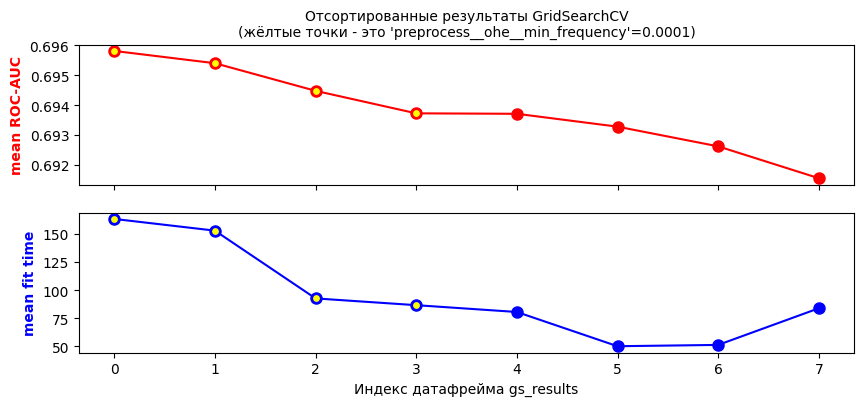

,model__max_depth,model__max_samples,model__min_samples_leaf,model__n_estimators,preprocess__ohe__min_frequency,rank_test_score,mean_test_score,mean_fit_time
0,60,0.50,5,200,0.0001,1,0.695807,163.335994
1,60,0.50,10,200,0.0001,2,0.695397,152.919120
2,60,0.25,5,200,0.0001,3,0.694475,92.590153
3,60,0.25,10,200,0.0001,4,0.693723,86.565540
4,60,0.50,10,200,0.0010,5,0.693708,80.501201
5,60,0.25,10,200,0.0010,6,0.693279,50.025000
6,60,0.25,5,200,0.0010,7,0.692621,51.185237
7,60,0.50,5,200,0.0010,8,0.691557,83.797763


In [170]:
rf_pipe_gs_results = GridSearchCV_visualizer(
    rf_pipe_gs, 'preprocess__ohe__min_frequency', 0.0001, width=10, head=None
)
display(rf_pipe_gs_results)

In [171]:
rf_pipe = rf_pipe_gs.best_estimator_
rf_auc_mean, rf_auc_std = validate(rf_pipe, X_train_raw, y_train, skf)

Модель: Pipeline with RandomForestClassifier
Продолжительность валидации: 6.0 мин
ROC-AUC mean: 0.6924
ROC-AUC std:  0.0007


In [172]:
columns = pd.MultiIndex.from_product([['ROC-AUC'], ['mean', 'std']])
index = pd.Series(['default', 'optimized', 'difference'], name='RandomForestClassifier')
values = [[rf_default_auc_mean, rf_auc_mean, rf_auc_mean - rf_default_auc_mean],
          [rf_default_auc_std, rf_auc_std, rf_auc_std - rf_default_auc_std]]
pd.DataFrame(np.array(values).T, columns=columns, index=index).style.format("{:.4f}")

С помощью оптимизации удалось повысить ROC-AUC случайного леса на 0.0289, что существенно больше, чем у линейной регрессии. При этом, модель стала немного стабильнее.

### 2.5.3 MLPClassifier

In [173]:
print(preprocessor.get_params()['ohe__min_frequency'])

0.01


In [174]:
mlp = MLPClassifier(
    early_stopping=True,
    random_state=42
)
mlp_pipe = Pipeline([
        ('preprocess', preprocessor),
        ('model', mlp),
    ])
mlp_default_auc_mean, mlp_default_auc_std = (
    validate(mlp_pipe, X_train_raw, y_train, skf)
)

Модель: Pipeline with MLPClassifier
Продолжительность валидации: 0.9 мин
ROC-AUC mean: 0.6730
ROC-AUC std:  0.0011


Закомментированная сетка параметров `param_grid_all_tried` содержит все проверенные значения. Для экономии времени при демострации процесса оптимизации использована уменьшенная сетка параметров `param_grid_demo`.

In [175]:
%%time

# param_grid_all_tried = {
#     'preprocess__ohe__min_frequency': [1e-2, 1e-3, 1e-4, 5e-5],
#     'model__hidden_layer_sizes': [
#         (128,), (256,), (512,),
#         (128, 128), (256, 128),
#         (256, 256), (320, 256), (384, 256), (448, 256), (512, 256),
#         (256, 320), (320, 320),
#         (256, 384),
#     ],
#     'model__alpha': [1e-6, 1e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1],
#     'model__batch_size': [4096, 2048, 1024, 512],
#     'model__learning_rate_init': [1e-3, 3e-4, 2e-3, 5e-4],
#     'model__learning_rate': ['constant', 'adaptive'],
#     'model__epsilon': [1e-6, 1e-7, 1e-8],
# }

param_grid_demo = {
    'preprocess__ohe__min_frequency': [0.001, 0.0001],
    'model__hidden_layer_sizes': [(256, 128), (256, 256)],
    'model__batch_size': [4096, 2048],
}

strat_split_1 = StratifiedShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
# skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

mlp_pipe_gs = GridSearchCV(
    cv=strat_split_1,
    # cv=skf,
    scoring='roc_auc',
    estimator=mlp_pipe,
    param_grid=param_grid_demo,
    verbose=3,
    n_jobs=-1,
    # если не хватает памяти, тогда:
    # n_jobs=1,
    # pre_dispatch=1
)
mlp_pipe_gs.fit(X_train_raw, y_train)

Fitting 1 folds for each of 8 candidates, totalling 8 fits
CPU times: total: 14min 41s
Wall time: 8min 39s


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__batch_size': [4096, 2048], 'model__hidden_layer_sizes': [(256, ...), (256, ...)], 'preprocess__ohe__min_frequency': [0.001, 0.0001]}"
,scoring,'roc_auc'
,n_jobs,-1
,refit,True
,cv,StratifiedShu...ain_size=None)
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,steps,"[('prepare_for_ohe', ...), ('ohe', ...)]"


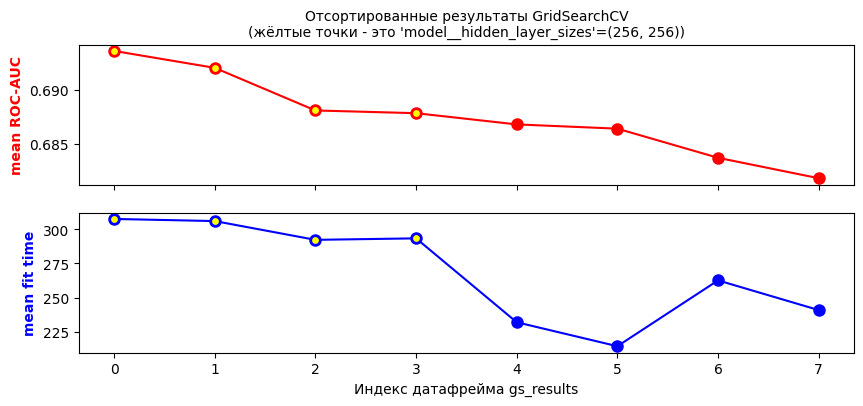

,model__batch_size,model__hidden_layer_sizes,preprocess__ohe__min_frequency,rank_test_score,mean_test_score,mean_fit_time
0,2048,"(256, 256)",0.0001,1,0.693577,307.585655
1,4096,"(256, 256)",0.0001,2,0.692010,306.027497
2,2048,"(256, 256)",0.0010,3,0.688063,292.273897
3,4096,"(256, 256)",0.0010,4,0.687811,293.370116
4,2048,"(256, 128)",0.0010,5,0.686771,231.904255
5,4096,"(256, 128)",0.0010,6,0.686377,214.350662
6,2048,"(256, 128)",0.0001,7,0.683678,262.579261
7,4096,"(256, 128)",0.0001,8,0.681786,240.830957


In [176]:
mlp_pipe_gs_results = GridSearchCV_visualizer(
    mlp_pipe_gs, 'model__hidden_layer_sizes', (256, 256), width=10, head=None
)
display(mlp_pipe_gs_results)

In [177]:
mlp_pipe = mlp_pipe_gs.best_estimator_
validate(mlp_pipe, X_train_raw, y_train, skf);

Модель: Pipeline with MLPClassifier
Продолжительность валидации: 3.3 мин
ROC-AUC mean: 0.6841
ROC-AUC std:  0.0059


Значение ROC-AUC, полученное с помощью кросс-валидации, оказалось ниже оценки на одном разбиении. Грубая оптимизация гиперпараметров с использованием кросс-валидации привела к тем же значениям параметров, кроме коэффициента регуляризации `alpha`, увеличение которого на два порядка улучшило качество по кросс-валидации. В целях экономии вычислительного времени выше показана оптимизация гиперпараметров по одному разбиению, а кросс-валидация используется для финальной оценки качества модели.

In [178]:
mlp_pipe.get_params()['model__alpha']

0.0001

In [179]:
mlp_pipe.set_params(model__alpha=0.01)
mlp_auc_mean, mlp_auc_std = validate(mlp_pipe, X_train_raw, y_train, skf)

Модель: Pipeline with MLPClassifier
Продолжительность валидации: 3.2 мин
ROC-AUC mean: 0.6873
ROC-AUC std:  0.0030


In [180]:
columns = pd.MultiIndex.from_product([['ROC-AUC'], ['mean', 'std']])
index = pd.Series(['default', 'optimized', 'difference'], name='MLPClassifier')
values = [[mlp_default_auc_mean, mlp_auc_mean, mlp_auc_mean - mlp_default_auc_mean],
          [mlp_default_auc_std, mlp_auc_std, mlp_auc_std - mlp_default_auc_std]]
pd.DataFrame(np.array(values).T, columns=columns, index=index).style.format("{:.4f}")

С помощью оптимизации удалось повысить ROC-AUC многослойного персептрона на 0.0143 - самый маленький прирост из трёх моделей. Оптимизированная модель гораздо менее стабильна, СКО увеличилось почти в 3 раза.

## 2.6 Выбор лучшей модели

In [181]:
columns = pd.MultiIndex.from_product([['ROC-AUC'], ['mean', 'std']])
index = pd.Series(
    ['LogisticRegression', 'RandomForestClassifier', 'MLPClassifier'],
    name='model'
)
values = [
    [lr_auc_mean, lr_auc_std],
    [rf_auc_mean, rf_auc_std],
    [mlp_auc_mean, mlp_auc_std]
]
pd.DataFrame(values, columns=columns, index=index).style.format("{:.4f}")

Наилучшие результаты демонстрирует RandomForestClassifier: максимальное значение ROC-AUC (0.6924) при минимальном СКО (0.0007). Это самая качественная и самая стабильная модель. Такой результат ожидаем, поскольку случайный лес хорошо подходит для работы с разреженными категориальными признаками после one-hot кодирования и эффективно учитывает взаимодействия между признаками. Ансамблевая природа модели обеспечивает снижение дисперсии. В качестве итоговой модели выбираем `RandomForestClassifier`.

## 2.7 Определение порога классификации

В условиях отсутствия информации о бизнес-стоимости ошибок и при сильном дисбалансе классов порог классификации определим по максимальному значению F1-score на out-of-fold вероятностях обучающей выборки как компромисс между precision и recall.

In [182]:
%%time
oof_proba = cross_val_predict(
    rf_pipe,
    X_train_raw,
    y_train,
    cv=skf,
    method="predict_proba"
)[:, 1]

CPU times: total: 58min 14s
Wall time: 5min 45s


In [183]:
round(oof_proba.max(), 3)

0.205

Посмотрим на различие распределений oof_proba у целевых и не целевых визитов.

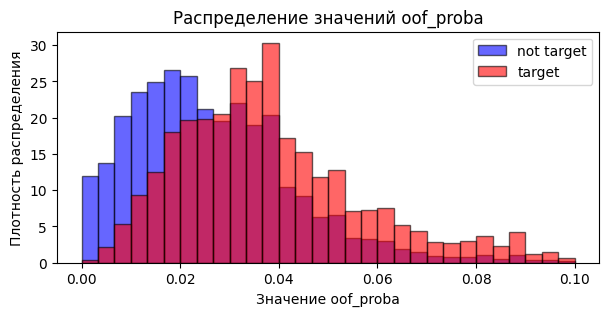

In [184]:
plt.figure(figsize=(7, 3))
bins = np.linspace(0, 0.1, 31)
plt.hist(oof_proba[y_train==0], bins=bins, density=True, color='b',
            alpha=0.6, edgecolor='k', label='not target')
plt.hist(oof_proba[y_train==1], bins=bins, density=True, color='r',
            alpha=0.6, edgecolor='k', label='target')
plt.title('Распределение значений oof_proba')
plt.xlabel('Значение oof_proba')
plt.ylabel('Плотность распределения')
plt.legend(loc='upper right');

Найдём порог при котором значение F1-score максимально.

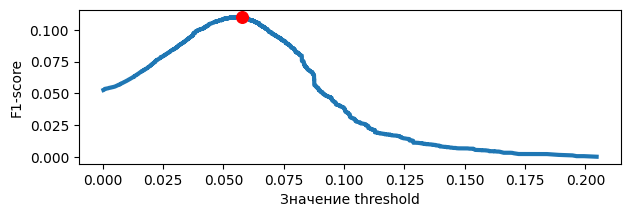

Оптимальное значение порога: 0.058
Максимальное значение F1-score: 0.11


In [185]:
precision, recall, pr_thresholds = precision_recall_curve(y_train, oof_proba)

with np.errstate(invalid="ignore", divide="ignore"): # чтобы не ругался
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1])

best_pr_idx = np.nanargmax(f1)
best_threshold = pr_thresholds[best_pr_idx]
f1_max = f1[best_pr_idx]

plt.figure(figsize=(7, 2))
plt.plot(pr_thresholds, f1, linewidth=3)
plt.scatter(best_threshold, f1_max, c='r', s=70, zorder=2)
plt.xlabel('Значение threshold')
plt.ylabel('F1-score')
plt.show()
print(f'Оптимальное значение порога: {round(best_threshold, 3)}'
      f'\nМаксимальное значение F1-score: {round(f1_max, 3)}')

Посмотрим на выбранную точку на кривой Precision–Recall.

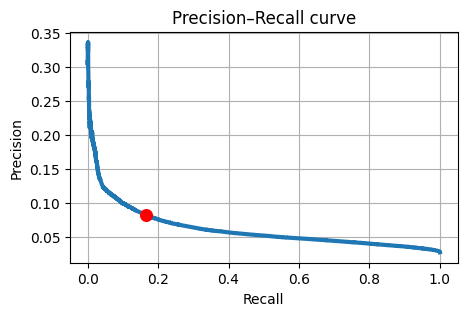

In [186]:
plt.figure(figsize=(5, 3))
plt.plot(recall[:-1], precision[:-1], linewidth=3)
plt.scatter(recall[best_pr_idx], precision[best_pr_idx], c='r', s=70, zorder=2)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall curve")
plt.grid(True)

Посмотрим на выбранную точку на ROC кривой.

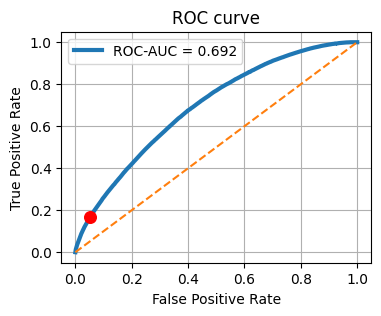

In [187]:
fpr, tpr, roc_thresholds = roc_curve(y_train, oof_proba)
best_roc_idx = np.argmin(np.abs(roc_thresholds - best_threshold))
roc_auc = roc_auc_score(y_train, oof_proba)

plt.figure(figsize=(4, 3))
plt.plot(fpr, tpr, linewidth=3, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.scatter(fpr[best_roc_idx], tpr[best_roc_idx], c='r', s=70, zorder=2)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve")
plt.legend()
plt.grid(True)

## 2.8 Confusion matrix

In [188]:
y_train_pred = (oof_proba >= best_threshold).astype(int)
confusion_matrix(y_train, y_train_pred)

array([[1373112,   74670],
       [  33549,    6702]], dtype=int64)

Оптимизация по F1-score привела к выбору порога, при котором модель допускает значительное число ложных срабатываний (false positives) при recall порядка 17%, что отражает компромиссный характер критерия F1-score в условиях сильного дисбаланса классов и указывает на необходимость учёта бизнес-ограничений при реальном применении модели.

# 3 Evaluation

In [189]:
df_test_raw = pd.read_pickle('./data/processed/df_test_raw.pkl')
X_test_raw = df_test_raw.drop(columns='target')
y_test = df_test_raw['target']
y_test_proba = rf_pipe.predict_proba(X_test_raw)[:, 1] # probability of the class with the greater label
auc = roc_auc_score(y_test, y_test_proba)
print(f'ROC-AUC: {auc:.2f}')

ROC-AUC: 0.70


In [190]:
y_test_pred = (y_test_proba >= best_threshold).astype(int)
confusion_matrix(y_test, y_test_pred)

array([[343418,  18528],
       [  8383,   1680]], dtype=int64)

На тестовой выборке модель достигла значения ROC-AUC 0.70, что соответствует заданию (≈0.65), и подтверждает успешное решение задачи предсказания совершения целевого действия. При использовании порога классификации, оптимизированного по F1-score на обучающей выборке, модель демонстрирует компромисс между precision и recall, сопровождающийся значительным числом ложных срабатываний, что указывает на необходимость учёта бизнес-информации при практическом применении модели.

Если ноутбук выполнен целиком, тогда рассчитаем общую продолжительность выполнения. Если не было остановок из-за ошибок, то это машинное время.

In [191]:
try: start_read
except NameError: pass
else:
    total_duration = format_duration(time.time() - start_read)
    print('Продолжительность выполнения всего ноутбука:', total_duration)

Продолжительность выполнения всего ноутбука: 62.4 мин.
